# FIG 3 — From feature tables to classifier performance

This notebook documents how the results shown in FIG 3 were generated, end to end: input feature tables → feature selection → classifier construction and training → evaluation on the external centers → saved plot data → FIG 3 and its AUC table.

It is a reduced version of `0_FINAL_pipe_GT_from_GH_genera_joblib.ipynb`. **Cells are not meant to be re-run here:** the outputs stored in each cell are the ones obtained in the original runs, and are kept so the whole chain can be read from the inputs to the final figure.

## Overall structure

The pipeline is executed **four times**, once for each value of `DSET_TYPE`. Only that variable changes; every other cell is identical.

| `DSET_TYPE` | Construction centers (US-MRI, PI-CAI) | External centers (NOVARA, TORINO) |
|---|---|---|
| `GT` | ground-truth lesions | ground-truth lesions |
| `MIXED_GT_TRAIN` | ground-truth lesions | detected lesions |
| `SURROGATE` | detected lesions | detected lesions |
| `MIXED_SURR_TRAIN` | detected lesions | ground-truth lesions |

Each run writes `report_final/plot_data/{DSET_TYPE}_classification_*.csv` (ROC points, metrics, feature importance, ...). The last cell of the notebook reads these four sets of files and draws FIG 3, plus `report_final/three_rows_auc_table.csv`.

## Notes on the stored outputs

- Execution counts are not sequential: the stored outputs come from different executions of the source notebook, not from a single top-to-bottom run.
- Data-loading outputs (GT loader) refer to the `GT` run. The evaluation cell ends with `Saved plot data with prefix: report_final/plot_data/MIXED_SURR_TRAIN_classification`, i.e. it is the output of the last run executed.
- The results of the other runs are not stored as cell outputs; they are only available through the saved CSV files and through the final figure.

## Inputs

Paths are relative to the project folder.

- `feature_tables_FINAL_2D/T2_lesion_iqr_zscore_stats2D_apply2D_lesionsrc_original__ADC_lesion_iqr_zscore_stats2D_apply2D_lesionsrc_original_BIN_16/` — `images_clean_*.csv`, `radiomics_clean_*.csv`, `labels_clean_*.csv`
- `feature_tables/psa_density_all.csv`, `feature_tables/valid_columns.csv`, `labels_scanner_uptodate.csv`
- Segmentation-model predictions: `../for_uunet/images_preds_NEW.csv`, `../for_uunet/df_features_preds_NEW.csv`, `../for_uunet/images_preds_TRAIN_NEW.csv`, `../for_uunet/df_features_preds_TRAIN_NEW.csv`

## 1. Libraries

In [1]:
# ===== IMPORT LIBRARIES =====

# Core libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

# Medical imaging
import nibabel as nib

# Scikit-learn: Base
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.model_selection import StratifiedKFold, cross_val_score, GridSearchCV
from sklearn.metrics import (roc_auc_score, roc_curve, classification_report, 
                           confusion_matrix, accuracy_score, precision_score, 
                           recall_score, f1_score)
from sklearn.utils.validation import check_is_fitted

# Scikit-learn: Preprocessing
from sklearn.preprocessing import (StandardScaler, MinMaxScaler, RobustScaler,
                                 Normalizer, PowerTransformer, QuantileTransformer)

# Scikit-learn: Feature Selection
from sklearn.feature_selection import (SelectKBest, f_classif, mutual_info_classif, 
                                     chi2, SelectPercentile, RFE, RFECV, SelectFromModel)
from sklearn.cluster import AffinityPropagation

# Scikit-learn: Linear Models
from sklearn.linear_model import (LogisticRegression, SGDClassifier, RidgeClassifier, 
                                PassiveAggressiveClassifier, LassoCV)

# Scikit-learn: Other Classifiers
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis, QuadraticDiscriminantAnalysis
from sklearn.ensemble import (RandomForestClassifier, ExtraTreesClassifier, 
                            GradientBoostingClassifier)

# Imbalanced-learn: Sampling
from imblearn.over_sampling import (SMOTE, ADASYN, BorderlineSMOTE, SVMSMOTE, 
                                  RandomOverSampler)
from imblearn.under_sampling import (RandomUnderSampler, EditedNearestNeighbours)
from imblearn.combine import (SMOTEENN, SMOTETomek)
from imblearn.pipeline import Pipeline as ImbPipeline


from scipy import stats
import numpy as np
from sklearn.metrics import roc_auc_score


## 2. Data loaders

`import_gt_dataset` loads the ground-truth radiomic feature table, labels (Gleason Grade Group `GG`, center, scanner) and PSA density, and tags each case with its center (US-MRI, PI-CAI, NOVARA, TORINO).
`import_pred_dataset` loads the same information for the lesions detected by the segmentation model and aligns the feature columns with the GT table. It also provides the Dice score against the GT lesion, used later to keep only detected lesions (`dice > 0`).

In [2]:
from pathlib import Path
import pandas as pd
def import_gt_dataset():
    
    df_psa_all = pd.read_csv('feature_tables/psa_density_all.csv')

    folders = ['T2_ring_iqr_zscore_stats2D_apply2D__ADC_ring_iqr_zscore_stats2D_apply2D_BIN_16',
    'T2_whole_prostate_iqr_zscore_stats2D_apply2D__ADC_whole_prostate_iqr_zscore_stats2D_apply2D_BIN_16',
    'T2_prostate_minus_lesion_iqr_zscore_stats2D_apply2D__ADC_prostate_minus_lesion_iqr_zscore_stats2D_apply2D_BIN_16',
    'T2_lesion_iqr_zscore_stats2D_apply2D_lesionsrc_original__ADC_lesion_iqr_zscore_stats2D_apply2D_lesionsrc_original_BIN_16',
    'T2_none_iqr_zscore_stats2D_apply2D__ADC_none_iqr_zscore_stats2D_apply2D_BIN_16']


    folder = folders[3]

    base = Path(f"feature_tables_FINAL_2D/{folder}")

    images_path = next(base.glob("images_clean_*.csv"))
    radiomics_path = next(base.glob("radiomics_clean_*.csv"))
    labels_path = next(base.glob("labels_clean_*.csv"))

    images_all_gt = pd.read_csv(images_path)
    df_results_all_gt = pd.read_csv(radiomics_path)
    labels_all_gt = pd.read_csv(labels_path)
    #labels_all_gt = pd.read_csv('labels_scanner_uptodate.csv')

    print(images_path.name)
    print(radiomics_path.name)
    print(labels_path.name)

    df_results_all_gt = df_results_all_gt.transpose()[14:].transpose()#.drop(columns = ['T2_voxels','ADC_voxels'])
    df_psa_all = pd.read_csv('feature_tables/psa_density_all.csv')
    labels_all_gt['psa_density'] = df_psa_all['psa_density']
    labels_all_gt['scanner'] = pd.read_csv('labels_scanner_uptodate.csv')['scanner']

    df_results_all_gt['psa_density'] = df_psa_all['psa_density']
    #### here I'm just adding labels related to scanners

    IDX_US = 876
    IDX_PICAI = 425
    IDX_NOV = 77

    images_us = images_all_gt[:IDX_US].reset_index(drop = True)
    df_results_us = df_results_all_gt.iloc[:IDX_US].reset_index(drop = True)
    labels_us = labels_all_gt.iloc[:IDX_US].reset_index(drop = True)

    images_nov = images_all_gt[IDX_US + IDX_PICAI:IDX_US + IDX_PICAI + IDX_NOV].reset_index(drop=True)
    df_results_nov = df_results_all_gt.iloc[IDX_US + IDX_PICAI:IDX_US + IDX_PICAI + IDX_NOV].reset_index(drop=True)
    labels_nov = labels_all_gt.iloc[IDX_US + IDX_PICAI:IDX_US + IDX_PICAI + IDX_NOV].reset_index(drop=True)

    images_tor = images_all_gt[IDX_US + IDX_PICAI + IDX_NOV: ].reset_index(drop=True)
    df_results_tor = df_results_all_gt.iloc[IDX_US + IDX_PICAI + IDX_NOV:  ].reset_index(drop=True)
    labels_tor = labels_all_gt.iloc[IDX_US + IDX_PICAI + IDX_NOV: ].reset_index(drop=True)

    images_prostatex = images_all_gt[IDX_US :IDX_US + IDX_PICAI].reset_index(drop=True)
    df_results_prostatex = df_results_all_gt.iloc[IDX_US :IDX_US + IDX_PICAI].reset_index(drop=True)
    labels_prostatex = labels_all_gt.iloc[IDX_US :IDX_US + IDX_PICAI].reset_index(drop=True)

    labels_us['center'] = 'US-MRI'
    labels_nov['center'] = 'NOVARA'
    labels_tor['center'] = 'TORINO'
    labels_prostatex['center'] = 'PI-CAI'
    labels_all_gt = pd.concat([labels_us, labels_prostatex, labels_nov, labels_tor], ignore_index=True)#.drop(columns = 'Unnamed: 0')
    labels_all_gt['case_id'] = images_all_gt['case_id']

    # es: "SIEMENS-Skyra-3.0" -> tesla = 3.0
    labels_all_gt["tesla"] = labels_all_gt["scanner"].str.extract(r'-(\d+(?:\.\d+)?)$')[0].astype(float)
    images_all_gt['tesla'] = labels_all_gt['tesla']
    images_all_gt['scanner'] = labels_all_gt['scanner']
    images_all_gt['center'] = labels_all_gt['center']

    ## keep only numeric feature

    valid_columns = pd.read_csv('feature_tables/valid_columns.csv')['0'].tolist()
    df_results_all_gt = df_results_all_gt[valid_columns + ['psa_density']]
    labels_all_gt['scanner_c'] = labels_all_gt['scanner']+'_'+labels_all_gt['center']
    df_results_all_gt = df_results_all_gt.astype(float)
    return images_all_gt, df_results_all_gt, labels_all_gt

def import_pred_dataset():
    images_all_gt, df_results_all_gt, labels_all_gt = import_gt_dataset()

    path_label_gt = (
        pd.concat([labels_all_gt, images_all_gt], axis=1)
        .drop(columns='Unnamed: 0', errors='ignore')
        .loc[:, lambda x: ~x.columns.duplicated()]
    )

    images_val_pred = pd.read_csv('../for_uunet/images_preds_NEW.csv')
    feat_val_pred = pd.read_csv('../for_uunet/df_features_preds_NEW.csv')
    print(f"Predizioni val: images {images_val_pred.shape}, features {feat_val_pred.shape}")

    images_val_pred.loc[images_val_pred['idx'] < 77, 'center'] = 'Novara'

    images_train_pred = pd.read_csv('../for_uunet/images_preds_TRAIN_NEW.csv')
    feat_train_pred = pd.read_csv('../for_uunet/df_features_preds_TRAIN_NEW.csv')
    print(f"Predizioni train: images {images_train_pred.shape}, features {feat_train_pred.shape}")

    images_train_pred = images_train_pred.drop(columns='center', errors='ignore')

    # evita colonne duplicate già all'inizio
    images_val_pred = images_val_pred.loc[:, ~images_val_pred.columns.duplicated()]
    images_train_pred = images_train_pred.loc[:, ~images_train_pred.columns.duplicated()]
    feat_val_pred = feat_val_pred.loc[:, ~feat_val_pred.columns.duplicated()]
    feat_train_pred = feat_train_pred.loc[:, ~feat_train_pred.columns.duplicated()]

    # metadata GT da attaccare alle predizioni
    gt_meta_cols = ['center', 'scanner', 'psa_density', 'nii_segms', 'tesla']

    gt_meta = (
        path_label_gt[gt_meta_cols]
        .rename(columns={'nii_segms': 'gt_path'})
        .drop_duplicates(subset=['gt_path'])
        .loc[:, lambda x: ~x.columns.duplicated()]
    )

    images_train_pred = images_train_pred.merge(
        gt_meta,
        on='gt_path',
        how='left'
    )

    images_val_pred = images_val_pred.merge(
        gt_meta,
        on='gt_path',
        how='left',
        suffixes=('', '_gt')
    )

    # se dopo il merge rimangono colonne *_gt, usa quelle solo se servono
    for col in ['center', 'scanner', 'psa_density', 'tesla']:
        gt_col = f'{col}_gt'
        if gt_col in images_val_pred.columns:
            images_val_pred[col] = images_val_pred[col].fillna(images_val_pred[gt_col])
            images_val_pred = images_val_pred.drop(columns=gt_col)

    # togli duplicati dopo merge
    images_val_pred = images_val_pred.loc[:, ~images_val_pred.columns.duplicated()]
    images_train_pred = images_train_pred.loc[:, ~images_train_pred.columns.duplicated()]

    # aggiungi psa_density alle features
    feat_val_pred['psa_density'] = images_val_pred['psa_density'].values
    feat_train_pred['psa_density'] = images_train_pred['psa_density'].values

    # allinea colonne features con GT
    common_cols = sorted(set(df_results_all_gt.columns).intersection(feat_train_pred.columns))

    df_results_all = df_results_all_gt[common_cols]
    feat_train_pred = feat_train_pred[common_cols]
    feat_val_pred = feat_val_pred[common_cols]

    # split
    images_val_pred['split'] = 'external'
    images_train_pred['split'] = 'train'

    # rinomina path in formato compatibile con GT
    rename_map = {
        'adc_path': 'nii_images_ADC',
        't2_path': 'nii_images',
        'mask_path': 'nii_segms'
    }

    images_val_pred = images_val_pred.rename(columns=rename_map)
    images_train_pred = images_train_pred.rename(columns=rename_map)

    # colonne labels coerenti con labels_all_gt
    label_base_cols = (
        labels_all_gt
        .drop(columns=['Subject', 'scanner_c'], errors='ignore')
        .columns
        .tolist()
    )

    extra_cols = [
        'dice',
        'is_tp',
        'is_fp',
        'dice_vs_gt_global',
        'overlap_nonzero'
    ]

    label_cols = label_base_cols + extra_cols

    # tieni solo colonne che esistono davvero
    label_cols_val = [c for c in label_cols if c in images_val_pred.columns]
    label_cols_train = [c for c in label_cols if c in images_train_pred.columns]

    labels_val_pred = images_val_pred[label_cols_val].copy()
    labels_train_pred = images_train_pred[label_cols_train].copy()

    labels_val_pred = labels_val_pred.loc[:, ~labels_val_pred.columns.duplicated()]
    labels_train_pred = labels_train_pred.loc[:, ~labels_train_pred.columns.duplicated()]

    images_all_PRED = pd.concat([images_train_pred, images_val_pred], axis=0, ignore_index=True)
    labels_all_PRED = pd.concat([labels_train_pred, labels_val_pred], axis=0, ignore_index=True)
    df_results_all_PRED = pd.concat([feat_train_pred, feat_val_pred], axis=0, ignore_index=True)

    return images_all_PRED, df_results_all_PRED, labels_all_PRED

## 3. Cross-validation function

`evaluate_pipeline_construction_cv_with_threshold` runs a nested cross-validation on the construction set: the inner loop tunes the hyperparameters with Optuna, the outer loop provides out-of-fold scores. From the training-derived scores it computes several decision thresholds (Youden, prevalence, F2, sensitivity 90%, specificity 90%, top-left).

In [3]:
import numpy as np
import optuna

from sklearn.base import clone
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.metrics import roc_auc_score, roc_curve, precision_recall_curve

from collections import Counter, defaultdict

# === 1️⃣ funzione per consensus anche su parametri continui ===
def consensus_continuous(best_params_per_fold):

    if not best_params_per_fold:
        return {}, 0

    keys = best_params_per_fold[0].keys()
    consensus = {}
    support = defaultdict(int)

    for k in keys:
        values = [p[k] for p in best_params_per_fold if k in p]
        if not values:
            continue

        if k.endswith('__C') or k.endswith('__alpha'):
            consensus[k] = float(np.exp(np.median(np.log(values))))
        elif k.endswith('__l1_ratio'):
            consensus[k] = float(np.median(values))
        else:
            c = Counter(values).most_common(1)[0]
            consensus[k] = c[0]
            support[k] = c[1]

    support_mean = int(np.mean(list(support.values()) or [len(best_params_per_fold)]))
    return consensus, support_mean


def make_optuna_callback(print_every=5):
    def callback(study, trial):
        if trial.value is None:
            return
        if (trial.number + 1) % print_every == 0:
            print(
                f"      trial {trial.number + 1:3d} | "
                f"current={trial.value:.4f} | "
                f"best={study.best_value:.4f} | "
                f"best_trial={study.best_trial.number}"
            )
    return callback


class StopWhenNoImprovementCallback:
    def __init__(self, patience=15, min_delta=1e-3):
        self.patience = patience
        self.min_delta = min_delta
        self.best_value = -np.inf
        self.best_trial_number = -1

    def __call__(self, study, trial):
        if trial.value is None:
            return

        if trial.value > self.best_value + self.min_delta:
            self.best_value = trial.value
            self.best_trial_number = trial.number

        if trial.number - self.best_trial_number >= self.patience:
            print(
                f"      early stop at trial {trial.number + 1}: "
                f"no improvement > {self.min_delta} "
                f"for {self.patience} trials"
            )
            study.stop()


def _positive_scores_from_fitted_model(model, X, where=""):
    clf = model.named_steps['clf']

    if hasattr(clf, "predict_proba"):
        proba = np.asarray(model.predict_proba(X))

        if proba.ndim != 2:
            raise ValueError(f"{where} predict_proba must be 2D, got shape={proba.shape}")

        classes = np.asarray(clf.classes_)

        if proba.shape[1] != len(classes):
            raise ValueError(
                f"{where} mismatch between proba columns {proba.shape[1]} and classes {len(classes)}"
            )

        if 1 in classes:
            pos_idx = int(np.where(classes == 1)[0][0])
            return proba[:, pos_idx]

        if np.array_equal(classes, [0]) or (len(classes) == 1 and classes[0] == 0):
            print(f"      ⚠️ {where}: classifier saw only class 0; returning all-zero scores")
            return np.zeros(len(X), dtype=float)

        if np.array_equal(classes, [1]) or (len(classes) == 1 and classes[0] == 1):
            print(f"      ⚠️ {where}: classifier saw only class 1; returning all-one scores")
            return np.ones(len(X), dtype=float)

        raise ValueError(f"{where} unexpected classes_={classes}")

    if hasattr(clf, "decision_function"):
        return model.decision_function(X)

    raise ValueError(f"{where} classifier supports neither predict_proba nor decision_function")


def _manual_oof_scores(pipe, X, y, cv, where="OOF"):
    scores = np.empty(len(X), dtype=float)

    for inner_fold_id, (tr_idx, va_idx) in enumerate(cv.split(X, y), start=1):
        X_tr_in = X.iloc[tr_idx]
        y_tr_in = y.iloc[tr_idx]
        X_va_in = X.iloc[va_idx]

        model = clone(pipe)
        model.fit(X_tr_in, y_tr_in)

        scores[va_idx] = _positive_scores_from_fitted_model(
            model, X_va_in, where=f"{where} inner-fold-{inner_fold_id}"
        )

    return scores


def _compute_train_thresholds(
    y_true,
    scores,
    beta=2.0,
    sens_target=0.90,
    spec_target=0.90
):
    """
    Calcola diversi threshold TRAIN-derived su score OOF.
    Restituisce un dict con threshold e metriche associate.
    """
    out = {}

    y_true = np.asarray(y_true).astype(int)
    scores = np.asarray(scores, dtype=float)

    # =========================
    # ROC-based thresholds
    # =========================
    fpr, tpr, thr = roc_curve(y_true, scores)
    spec = 1.0 - fpr

    # Youden
    J = tpr - fpr
    idx_youden = int(np.argmax(J))
    out['t_youden'] = float(thr[idx_youden])
    out['youden_score'] = float(J[idx_youden])

    # Closest top-left
    dist2 = (1.0 - tpr) ** 2 + fpr ** 2
    idx_topleft = int(np.argmin(dist2))
    out['t_topleft'] = float(thr[idx_topleft])

    # Sensitivity-constrained
    valid_sens = np.where(tpr >= sens_target)[0]
    if len(valid_sens) > 0:
        idx_sens = valid_sens[np.argmin(fpr[valid_sens])]  # massima specificità tra quelle valide
        out[f't_sens_{int(round(100 * sens_target))}'] = float(thr[idx_sens])
    else:
        out[f't_sens_{int(round(100 * sens_target))}'] = np.nan

    # Specificity-constrained
    valid_spec = np.where(spec >= spec_target)[0]
    if len(valid_spec) > 0:
        idx_spec = valid_spec[np.argmax(tpr[valid_spec])]  # massima sensitività tra quelle valide
        out[f't_spec_{int(round(100 * spec_target))}'] = float(thr[idx_spec])
    else:
        out[f't_spec_{int(round(100 * spec_target))}'] = np.nan

    # Prevalence threshold
    prevalence = float(np.mean(y_true))
    out['t_prev'] = float(np.quantile(scores, 1.0 - prevalence))

    # =========================
    # PR-based thresholds
    # =========================
    prec, rec, thr_pr = precision_recall_curve(y_true, scores)

    # NB: precision_recall_curve restituisce prec/rec di lunghezza len(thr_pr)+1
    if len(thr_pr) > 0:
        prec_use = prec[:-1]
        rec_use = rec[:-1]

        # F2
        beta2 = beta ** 2
        fbeta = (1 + beta2) * prec_use * rec_use / (beta2 * prec_use + rec_use + 1e-12)
        idx_fbeta = int(np.argmax(fbeta))
        out[f't_f{int(beta) if float(beta).is_integer() else beta}'] = float(thr_pr[idx_fbeta])
        out[f'f{int(beta) if float(beta).is_integer() else beta}_score'] = float(fbeta[idx_fbeta])
    else:
        out[f't_f{int(beta) if float(beta).is_integer() else beta}'] = np.nan
        out[f'f{int(beta) if float(beta).is_integer() else beta}_score'] = np.nan

    return out


def evaluate_pipeline_construction_cv_with_threshold(
    scaler_name,
    imbalance_name,
    selector_name,
    classifier_name,
    X_constr,
    y_constr,
    use_youden=True,
    use_tprev=True,
    use_tf2=True,
    use_tsens90=True,
    use_tspec90=True,
    use_ttopleft=True,
    n_splits_outer=5,
    n_splits_inner=5,
    n_trials=25,
    timeout=300,
    n_jobs_optuna=4,
    print_every=5,
    early_stop_patience=15,
    early_stop_min_delta=1e-3,
    random_state=43
):
    """
    Model selection SOLO sul construction set (USMRI + PICAI insieme).

    Fa:
    - outer CV stratificata sul construction per stimare performance interna
    - Optuna dentro ogni outer-fold
    - soglie train-derived calcolate SOLO sul train via OOF

    Non usa Novara/Torino.
    Non fa stress test US<->PICAI: quello conviene tenerlo separato.
    """

    from imblearn.pipeline import Pipeline as ImbPipeline
    from sklearn.pipeline import Pipeline

    # =========================
    # 1. Costruisci pipeline base
    # =========================
    steps = [
        ('scaler', scalers_options[scaler_name]),
        ('selector', feature_selectors_options[selector_name]),
    ]

    if imbalance_options[imbalance_name] is not None:
        steps.append(('imbalance', imbalance_options[imbalance_name]))
        base_pipe = ImbPipeline(steps + [('clf', classifiers_options[classifier_name])])
    else:
        base_pipe = Pipeline(steps + [('clf', classifiers_options[classifier_name])])

    # =========================
    # 2. Spazio iperparametri
    # =========================
    def suggest_params(trial, classifier_name):
        if classifier_name == 'logistic_l2':
            return {'C': trial.suggest_float('C', 1e-2, 1e3, log=True)}
        elif classifier_name == 'logistic_l1':
            return {'C': trial.suggest_float('C', 1e-2, 1e3, log=True)}
        elif classifier_name == 'logistic_elastic':
            return {
                'C': trial.suggest_float('C', 1e-2, 1e3, log=True),
                'l1_ratio': trial.suggest_float('l1_ratio', 0.0, 1.0)
            }
        elif classifier_name == 'sgd_logistic':
            return {
                'alpha': trial.suggest_float('alpha', 1e-6, 1e-2, log=True),
                'l1_ratio': trial.suggest_float('l1_ratio', 0.0, 1.0)
            }
        elif classifier_name == 'svm_linear':
            return {'C': trial.suggest_float('C', 1e-2, 1e2, log=True)}
        elif classifier_name == 'logistic_base':
            return {'C': trial.suggest_float('C', 1e-2, 1e2, log=True)}
        else:
            return {}

    # =========================
    # 3. Outer CV sul construction
    # =========================
    outer_cv = StratifiedKFold(
        n_splits=n_splits_outer,
        shuffle=True,
        random_state=random_state
    )

    outer_auc_scores = []

    outer_youden_scores = []
    outer_thresholds = []

    outer_thresholds_prev = []

    outer_thresholds_f2 = []
    outer_f2_scores = []

    outer_thresholds_sens90 = []
    outer_thresholds_spec90 = []
    outer_thresholds_topleft = []

    best_params_per_fold = []
    optuna_histories = []

    for fold_id, (tr_idx, va_idx) in enumerate(outer_cv.split(X_constr, y_constr), start=1):
        X_tr = X_constr.iloc[tr_idx]
        y_tr = y_constr.iloc[tr_idx]
        X_va = X_constr.iloc[va_idx]
        y_va = y_constr.iloc[va_idx]

        print(f"   Outer fold {fold_id}/{n_splits_outer} | train={len(tr_idx)} | val={len(va_idx)}")

        class_counts = y_tr.value_counts()
        min_class_count = class_counts.min()

        if min_class_count < 2:
            raise ValueError(
                f"Outer fold {fold_id}: a class in training has <2 samples, "
                f"cannot run StratifiedKFold."
            )

        inner_splits_eff = min(n_splits_inner, int(min_class_count))

        inner_cv = StratifiedKFold(
            n_splits=inner_splits_eff,
            shuffle=True,
            random_state=random_state
        )

        def objective(trial):
            params = suggest_params(trial, classifier_name)
            pipe = base_pipe.set_params(**{f'clf__{k}': v for k, v in params.items()})

            aucs = cross_val_score(
                pipe,
                X_tr,
                y_tr,
                scoring='roc_auc',
                cv=inner_cv,
                n_jobs=1
            )
            return float(np.mean(aucs))

        study = optuna.create_study(
            direction='maximize',
            sampler=optuna.samplers.TPESampler(seed=42)
        )

        callbacks = [
            make_optuna_callback(print_every=print_every),
            StopWhenNoImprovementCallback(
                patience=early_stop_patience,
                min_delta=early_stop_min_delta
            )
        ]

        study.optimize(
            objective,
            n_trials=n_trials,
            timeout=timeout,
            n_jobs=n_jobs_optuna,
            show_progress_bar=False,
            callbacks=callbacks
        )

        best_params = study.best_params
        best_params_per_fold.append(best_params)

        trial_values = [t.value for t in study.trials if t.value is not None]
        best_so_far = np.maximum.accumulate(trial_values).tolist() if len(trial_values) else []

        optuna_histories.append({
            'fold_id': fold_id,
            'trial_values': trial_values,
            'best_so_far': best_so_far,
            'best_value': float(study.best_value),
            'best_trial': int(study.best_trial.number),
            'n_trials_done': len(trial_values)
        })

        print(
            f"      best outer-fold-{fold_id} inner-CV AUC = {study.best_value:.4f} "
            f"| best params = {best_params}"
        )

        # fit finale sul training dell'outer fold
        pipe = base_pipe.set_params(**{f'clf__{k}': v for k, v in best_params.items()})
        pipe.fit(X_tr, y_tr)

        # performance su validation dell'outer fold
        s_va = _positive_scores_from_fitted_model(pipe, X_va, where="VAL")
        auc = roc_auc_score(y_va, s_va)
        outer_auc_scores.append(float(auc))

        # OOF sul train per soglie TRAIN-derived
        if any([use_youden, use_tprev, use_tf2, use_tsens90, use_tspec90, use_ttopleft]):
            s_tr_oof = _manual_oof_scores(pipe, X_tr, y_tr, inner_cv, where="OOF")
            thr_dict = _compute_train_thresholds(
                y_true=y_tr,
                scores=s_tr_oof,
                beta=2.0,
                sens_target=0.90,
                spec_target=0.90
            )

        if use_youden:
            outer_thresholds.append(float(thr_dict['t_youden']))
            outer_youden_scores.append(float(thr_dict['youden_score']))

        if use_tprev:
            outer_thresholds_prev.append(float(thr_dict['t_prev']))

        if use_tf2:
            outer_thresholds_f2.append(float(thr_dict['t_f2']))
            outer_f2_scores.append(float(thr_dict['f2_score']))

        if use_tsens90:
            outer_thresholds_sens90.append(float(thr_dict['t_sens_90']))

        if use_tspec90:
            outer_thresholds_spec90.append(float(thr_dict['t_spec_90']))

        if use_ttopleft:
            outer_thresholds_topleft.append(float(thr_dict['t_topleft']))

    recommended_params, recommended_params_support = consensus_continuous(best_params_per_fold)

    result = {
        'scaler': scaler_name,
        'imbalance': imbalance_name,
        'selector': selector_name,
        'classifier': classifier_name,
        'median_auc_cv': float(np.median(outer_auc_scores)),
        'std_auc_cv': float(np.std(outer_auc_scores)),
        'cv_scores_auc': outer_auc_scores,
        'best_params_per_fold': best_params_per_fold,
        'recommended_params': recommended_params,
        'recommended_params_support': recommended_params_support,
        'optuna_histories': optuna_histories
    }

    if use_youden:
        result.update({
            'median_youden_cv': float(np.median(outer_youden_scores)),
            'std_youden_cv': float(np.std(outer_youden_scores)),
            'median_threshold_cv': float(np.median(outer_thresholds)),
            'std_threshold_cv': float(np.std(outer_thresholds)),
            'cv_thresholds': outer_thresholds,
            'cv_scores_youden': outer_youden_scores
        })

    if use_tprev:
        result.update({
            'median_threshold_prev_cv': float(np.median(outer_thresholds_prev)),
            'std_threshold_prev_cv': float(np.std(outer_thresholds_prev)),
            'cv_thresholds_prev': outer_thresholds_prev
        })

    if use_tf2:
        result.update({
            'median_f2_cv': float(np.median(outer_f2_scores)),
            'std_f2_cv': float(np.std(outer_f2_scores)),
            'median_threshold_f2_cv': float(np.nanmedian(outer_thresholds_f2)),
            'std_threshold_f2_cv': float(np.nanstd(outer_thresholds_f2)),
            'cv_thresholds_f2': outer_thresholds_f2,
            'cv_scores_f2': outer_f2_scores
        })

    if use_tsens90:
        result.update({
            'median_threshold_sens90_cv': float(np.nanmedian(outer_thresholds_sens90)),
            'std_threshold_sens90_cv': float(np.nanstd(outer_thresholds_sens90)),
            'cv_thresholds_sens90': outer_thresholds_sens90
        })

    if use_tspec90:
        result.update({
            'median_threshold_spec90_cv': float(np.nanmedian(outer_thresholds_spec90)),
            'std_threshold_spec90_cv': float(np.nanstd(outer_thresholds_spec90)),
            'cv_thresholds_spec90': outer_thresholds_spec90
        })

    if use_ttopleft:
        result.update({
            'median_threshold_topleft_cv': float(np.nanmedian(outer_thresholds_topleft)),
            'std_threshold_topleft_cv': float(np.nanstd(outer_thresholds_topleft)),
            'cv_thresholds_topleft': outer_thresholds_topleft
        })

    return result

## 4. Final classifier: scanner-wise mixture of bootstrap experts

`ScannerMixtureOfExpertsBootstrap` fits one set of bootstrap logistic-regression experts per scanner of the construction set and averages their probabilities. `compute_thresholds` derives the operating thresholds from the construction-set predictions.

In [4]:
import numpy as np
import pandas as pd
from sklearn.base import clone
from sklearn.metrics import roc_curve, precision_recall_curve

# =============================================================================
# 0. WRAPPER: MIXTURE OF EXPERTS + BOOTSTRAP PER SCANNER
# =============================================================================
class ScannerMixtureOfExpertsBootstrap:
    def __init__(
        self,
        base_pipeline,
        scanner_labels,
        min_samples=50,
        n_bootstrap=20,
        bootstrap_size=50,
        balanced_bootstrap=True,
        random_state=42,
        min_minority_for_smote=6,
    ):
        self.base_pipeline = base_pipeline
        self.scanner_labels = pd.Series(scanner_labels)
        self.min_samples = min_samples
        self.n_bootstrap = n_bootstrap
        self.bootstrap_size = bootstrap_size
        self.balanced_bootstrap = balanced_bootstrap
        self.random_state = random_state
        self.min_minority_for_smote = min_minority_for_smote

        self.experts_ = {}
        self.valid_scanners_ = []
        self.scanner_counts_ = None
        self.bootstrap_info_ = []

    def _sample_bootstrap_indices(self, y_scanner, rng):
        y_scanner = pd.Series(y_scanner)

        idx0 = y_scanner[y_scanner == 0].index.to_numpy()
        idx1 = y_scanner[y_scanner == 1].index.to_numpy()

        if len(idx0) == 0 or len(idx1) == 0:
            return None

        n_total = min(self.bootstrap_size, len(y_scanner)) if not self.balanced_bootstrap else self.bootstrap_size

        if self.balanced_bootstrap:
            n0 = n_total // 2
            n1 = n_total - n0

            boot0 = rng.choice(idx0, size=n0, replace=True)
            boot1 = rng.choice(idx1, size=n1, replace=True)
            boot_idx = np.concatenate([boot0, boot1])
            rng.shuffle(boot_idx)
            return boot_idx
        else:
            boot_idx = rng.choice(y_scanner.index.to_numpy(), size=n_total, replace=True)
            return boot_idx

    def _maybe_disable_sampler(self, pipeline, y_boot):
        y_boot = pd.Series(y_boot)
        min_class_count = y_boot.value_counts().min()

        if ("sampler" in pipeline.named_steps) and (min_class_count < self.min_minority_for_smote):
            pipeline = clone(pipeline)
            pipeline.set_params(sampler="passthrough")
        return pipeline

    def fit(self, X, y):
        rng = np.random.default_rng(self.random_state)

        scanner_series = self.scanner_labels.loc[X.index]
        self.scanner_counts_ = scanner_series.value_counts()
        self.valid_scanners_ = self.scanner_counts_[self.scanner_counts_ >= self.min_samples].index.tolist()

        self.experts_ = {}
        self.bootstrap_info_ = []

        print("\n1️⃣ SCANNER SELEZIONATI PER MIXTURE OF EXPERTS + BOOTSTRAP")
        print(self.scanner_counts_[self.scanner_counts_ >= self.min_samples].sort_values(ascending=False))
        print(f"\n   ✅ Numero scanner validi: {len(self.valid_scanners_)}")

        print(f"\n2️⃣ FIT DEGLI EXPERT BOOTSTRAP PER SCANNER")

        y = pd.Series(y, index=X.index)

        for scanner_name in self.valid_scanners_:
            mask_scanner = (scanner_series == scanner_name)

            X_scanner = X.loc[mask_scanner].copy()
            y_scanner = y.loc[mask_scanner].copy()

            if y_scanner.nunique() < 2:
                print(f"   ⚠️ Scanner {scanner_name}: una sola classe, skip")
                continue

            experts_scanner = []

            print(f"\n   🔹 Scanner {scanner_name} | n={len(X_scanner)}")

            for b in range(self.n_bootstrap):
                boot_idx = self._sample_bootstrap_indices(y_scanner, rng)

                if boot_idx is None:
                    print(f"      ⚠️ bootstrap {b+1}: classi insufficienti, skip")
                    continue

                X_boot = X_scanner.loc[boot_idx].copy()
                y_boot = y_scanner.loc[boot_idx].copy()

                if y_boot.nunique() < 2:
                    print(f"      ⚠️ bootstrap {b+1}: una sola classe dopo sampling, skip")
                    continue

                model = clone(self.base_pipeline)
                model = self._maybe_disable_sampler(model, y_boot)

                try:
                    model.fit(X_boot, y_boot)
                    experts_scanner.append(model)

                    class_counts = y_boot.value_counts().to_dict()
                    self.bootstrap_info_.append({
                        "scanner": scanner_name,
                        "bootstrap_id": b,
                        "n_samples": len(X_boot),
                        "class_0": class_counts.get(0, 0),
                        "class_1": class_counts.get(1, 0),
                        "sampler_active": int("sampler" in model.named_steps and model.named_steps["sampler"] != "passthrough")
                    })

                except Exception as e:
                    print(f"      ⚠️ bootstrap {b+1} failed: {type(e).__name__}: {e}")
                    continue

            if len(experts_scanner) > 0:
                self.experts_[scanner_name] = experts_scanner
                print(f"      ✅ Expert bootstrap fitted: {len(experts_scanner)}/{self.n_bootstrap}")
            else:
                print(f"      ❌ Nessun bootstrap valido per scanner {scanner_name}")

        n_total_experts = sum(len(v) for v in self.experts_.values())
        print(f"\n   ✅ Numero scanner con almeno un expert: {len(self.experts_)}")
        print(f"   ✅ Numero totale expert bootstrap allenati: {n_total_experts}")

        return self

    """
    def predict_proba(self, X):
        if len(self.experts_) == 0:
            raise ValueError("Nessun expert disponibile. Esegui prima fit().")

        scanner_level_probs = []

        for scanner_name, model_list in self.experts_.items():
            if len(model_list) == 0:
                continue

            boot_proba = np.column_stack([
                model.predict_proba(X)[:, 1]
                for model in model_list
            ])

            scanner_mean_proba = boot_proba.mean(axis=1)
            scanner_level_probs.append(scanner_mean_proba)

        if len(scanner_level_probs) == 0:
            raise ValueError("Nessuna probabilità disponibile dagli expert.")

        proba_matrix = np.column_stack(scanner_level_probs)
        p1 = proba_matrix.mean(axis=1)
        p0 = 1.0 - p1
        return np.column_stack([p0, p1])
    """
    def predict_proba(self, X):
        if len(self.experts_) == 0:
            raise ValueError("Nessun expert disponibile. Esegui prima fit().")

        scanner_level_probs = []
        scanner_names = []

        for scanner_name, model_list in self.experts_.items():
            if len(model_list) == 0:
                continue

            boot_proba = np.column_stack([
                model.predict_proba(X)[:, 1]
                for model in model_list
            ])

            scanner_mean_proba = boot_proba.mean(axis=1)

            scanner_level_probs.append(scanner_mean_proba)
            scanner_names.append(scanner_name)

        if len(scanner_level_probs) == 0:
            raise ValueError("Nessuna probabilità disponibile dagli expert.")

        proba_matrix = np.column_stack(scanner_level_probs)

        # PESI PER SCANNER: sqrt(n) = compromesso robusto
        weights = np.array([
            np.sqrt(self.scanner_counts_[scanner_name])
            #(self.scanner_counts_[scanner_name])
            for scanner_name in scanner_names
        ])

        weights = weights / weights.sum()

        p1 = np.average(proba_matrix, axis=1, weights=weights)
        p0 = 1.0 - p1

        return np.column_stack([p0, p1])

    def get_expert_proba_df(self, X):
        if len(self.experts_) == 0:
            raise ValueError("Nessun expert disponibile. Esegui prima fit().")

        out = {}
        for scanner_name, model_list in self.experts_.items():
            if len(model_list) == 0:
                continue

            boot_proba = np.column_stack([
                model.predict_proba(X)[:, 1]
                for model in model_list
            ])
            out[scanner_name] = boot_proba.mean(axis=1)

        return pd.DataFrame(out, index=X.index)


# =============================================================================
# HELPERS THRESHOLDS
# =============================================================================
def compute_thresholds(y_true, y_proba):
    y_true = np.asarray(y_true).astype(int)
    y_proba = np.asarray(y_proba).astype(float)

    fpr, tpr, roc_thresholds = roc_curve(y_true, y_proba)

    # 1) Youden
    youden = tpr - fpr
    thr_youden = roc_thresholds[np.argmax(youden)]

    # 2) Top-left (min distanza da (0,1))
    dist_topleft = np.sqrt(fpr**2 + (1 - tpr)**2)
    thr_topleft = roc_thresholds[np.argmin(dist_topleft)]

    # 3) sens90: threshold con TPR >= 0.90 e FPR minimo
    idx_sens90 = np.where(tpr >= 0.90)[0]
    thr_sens90 = roc_thresholds[idx_sens90[np.argmin(fpr[idx_sens90])]] if len(idx_sens90) > 0 else np.nan

    # 4) spec90: threshold con specificity >= 0.90 cioè FPR <= 0.10 e TPR massimo
    idx_spec90 = np.where(fpr <= 0.10)[0]
    thr_spec90 = roc_thresholds[idx_spec90[np.argmax(tpr[idx_spec90])]] if len(idx_spec90) > 0 else np.nan

    # 5) F2 threshold da PR curve
    precision, recall, pr_thresholds = precision_recall_curve(y_true, y_proba)
    # precision_recall_curve ritorna len(thresholds)=len(precision)-1
    precision_t = precision[:-1]
    recall_t = recall[:-1]
    beta2 = 2.0**2
    f2 = (1 + beta2) * precision_t * recall_t / (beta2 * precision_t + recall_t + 1e-12)
    thr_f2 = pr_thresholds[np.nanargmax(f2)] if len(pr_thresholds) > 0 else np.nan

    # 6) Prev threshold: assumo threshold = prevalenza positiva
    thr_prev = float(np.mean(y_true))

    return {
        "youden": float(thr_youden),
        "prev": float(thr_prev),
        "f2": float(thr_f2) if np.isfinite(thr_f2) else np.nan,
        "sens90": float(thr_sens90) if np.isfinite(thr_sens90) else np.nan,
        "spec90": float(thr_spec90) if np.isfinite(thr_spec90) else np.nan,
        "topleft": float(thr_topleft),
        "fpr": fpr,
        "tpr": tpr,
        "roc_thresholds": roc_thresholds,
    }



## 5. Run configuration

- Construction centers: US-MRI and PI-CAI. External validation centers: NOVARA and TORINO.
- `DSET_TYPE` selects which of the four runs is executed.
- Feature selection: greedy decorrelation (`SEL2`) with correlation threshold `CORR_THR = 0.7`, keeping `N_FEATURES = 10` radiomic features; PSA density is added on top (`USE_PSA = True`).
- `THRESHOLD` selects the operating threshold used for the external evaluation (`median_threshold_topleft_cv`).

In [5]:
THRESHOLDS = ['median_threshold_cv',
 'median_threshold_prev_cv',
 'median_threshold_f2_cv',
 'median_threshold_sens90_cv',
 'median_threshold_spec90_cv',
 'median_threshold_topleft_cv']


In [57]:
construction_centers = ["US-MRI", "PI-CAI"]
USE_PSA = True

DSET_TYPES = ['GT', 'MIXED_GT_TRAIN', 'SURROGATE', 'MIXED_SURR_TRAIN']
DSET_TYPE = DSET_TYPES[0]
#DSET_TYPE = 'SURROGATE' # 'SURROGATE' o 'GT' o 'MIXED_GT_TRAIN' o 'MIXED_SURR_TRAIN'
FEATURE_SELECTION_MODE = "SEL2"   # SEL1 | SEL2
CORR_THR = 0.7
N_FEATURES = 10

THRESHOLD = THRESHOLDS[5]

## 6. Build the dataset for the selected run

For `GT` the GT table is used as is. For `SURROGATE` only detected lesions (`dice > 0`) are kept. For `MIXED_GT_TRAIN` and `MIXED_SURR_TRAIN` the construction and external centers are taken from different tables (GT for one side, detected lesions for the other) and concatenated.

In [69]:


if DSET_TYPE == 'GT':
    images_all, df_results_all, labels_all = import_gt_dataset()
    print(images_all.shape, df_results_all.shape, labels_all.shape)
############
if DSET_TYPE == 'SURROGATE':
    images_all, df_results_all, labels_all = import_pred_dataset()

    labels_all["center"] = labels_all["center"].replace({
        "Novara": "NOVARA",
        "Torino": "TORINO"
    })

    # se vuoi allineare anche l'altro dataframe:
    images_all["center"] = images_all["center"].replace({
        "Novara": "NOVARA",
        "Torino": "TORINO"
        })
    
    
    images_out = images_all[labels_all['dice']==0]
    df_results_out = df_results_all[labels_all['dice']==0]
    labels_out = labels_all[labels_all['dice']==0]

    images_all = images_all[labels_all['dice']>0]
    df_results_all = df_results_all[labels_all['dice']>0]
    labels_all = labels_all[labels_all['dice']>0]



images_clean_T2_lesion_iqr_zscore_stats2D_apply2D_lesionsrc_original__ADC_lesion_iqr_zscore_stats2D_apply2D_lesionsrc_original_BIN_16.csv
radiomics_clean_T2_lesion_iqr_zscore_stats2D_apply2D_lesionsrc_original__ADC_lesion_iqr_zscore_stats2D_apply2D_lesionsrc_original_BIN_16.csv
labels_clean_T2_lesion_iqr_zscore_stats2D_apply2D_lesionsrc_original__ADC_lesion_iqr_zscore_stats2D_apply2D_lesionsrc_original_BIN_16.csv
(1462, 12) (1462, 201) (1462, 8)


In [70]:
labels_all_gt = labels_all
df_results_all_gt = df_results_all

In [530]:
if DSET_TYPE =='MIXED_GT_TRAIN':
    PRED = ['NOVARA','TORINO']
    GT = ['US-MRI', 'PI-CAI']
    
    ############
    images_all, df_results_all, labels_all = import_gt_dataset()
    labels_train = labels_all[images_all['center'].isin(GT)]
    df_results_train = df_results_all[images_all['center'].isin(GT)]
    images_train = images_all[images_all['center'].isin(GT)]
    
    ############
    images_all, df_results_all, labels_all = import_pred_dataset()

    labels_all["center"] = labels_all["center"].replace({
        "Novara": "NOVARA",
        "Torino": "TORINO"
    })

    # se vuoi allineare anche l'altro dataframe:
    images_all["center"] = images_all["center"].replace({
        "Novara": "NOVARA",
        "Torino": "TORINO"
        })
    
    
    images_out = images_all[labels_all['dice']==0]
    df_results_out = df_results_all[labels_all['dice']==0]
    labels_out = labels_all[labels_all['dice']==0]

    images_all = images_all[labels_all['dice']>0]
    df_results_all = df_results_all[labels_all['dice']>0]
    labels_all = labels_all[labels_all['dice']>0]
    
    labels_val = labels_all[images_all['center'].isin(PRED)]
    df_results_val = df_results_all[images_all['center'].isin(PRED)]
    images_val = images_all[images_all['center'].isin(PRED)]

    labels_all = pd.concat([labels_train, labels_val], axis=0, ignore_index=True)
    df_results_all = pd.concat([df_results_train, df_results_val], axis=0, ignore_index=True)
    images_all = pd.concat([images_train, images_val], axis=0, ignore_index=True)
    
elif DSET_TYPE =='MIXED_SURR_TRAIN':
    GT = ['NOVARA','TORINO']
    PRED = ['US-MRI', 'PI-CAI']
    
    ############
    images_all, df_results_all, labels_all = import_gt_dataset()
    labels_train = labels_all[images_all['center'].isin(GT)]
    df_results_train = df_results_all[images_all['center'].isin(GT)]
    images_train = images_all[images_all['center'].isin(GT)]
    
    ############
    images_all, df_results_all, labels_all = import_pred_dataset()

    labels_all["center"] = labels_all["center"].replace({
        "Novara": "NOVARA",
        "Torino": "TORINO"
    })

    # se vuoi allineare anche l'altro dataframe:
    images_all["center"] = images_all["center"].replace({
        "Novara": "NOVARA",
        "Torino": "TORINO"
        })
    
    
    images_out = images_all[labels_all['dice']==0]
    df_results_out = df_results_all[labels_all['dice']==0]
    labels_out = labels_all[labels_all['dice']==0]

    images_all = images_all[labels_all['dice']>0]
    df_results_all = df_results_all[labels_all['dice']>0]
    labels_all = labels_all[labels_all['dice']>0]
    
    labels_val = labels_all[images_all['center'].isin(PRED)]
    df_results_val = df_results_all[images_all['center'].isin(PRED)]
    images_val = images_all[images_all['center'].isin(PRED)]

    labels_all = pd.concat([labels_val, labels_train], axis=0, ignore_index=True)
    df_results_all = pd.concat([df_results_val, df_results_train], axis=0, ignore_index=True)
    images_all = pd.concat([images_val, images_train], axis=0, ignore_index=True)

images_clean_T2_lesion_iqr_zscore_stats2D_apply2D_lesionsrc_original__ADC_lesion_iqr_zscore_stats2D_apply2D_lesionsrc_original_BIN_16.csv
radiomics_clean_T2_lesion_iqr_zscore_stats2D_apply2D_lesionsrc_original__ADC_lesion_iqr_zscore_stats2D_apply2D_lesionsrc_original_BIN_16.csv
labels_clean_T2_lesion_iqr_zscore_stats2D_apply2D_lesionsrc_original__ADC_lesion_iqr_zscore_stats2D_apply2D_lesionsrc_original_BIN_16.csv
images_clean_T2_lesion_iqr_zscore_stats2D_apply2D_lesionsrc_original__ADC_lesion_iqr_zscore_stats2D_apply2D_lesionsrc_original_BIN_16.csv
radiomics_clean_T2_lesion_iqr_zscore_stats2D_apply2D_lesionsrc_original__ADC_lesion_iqr_zscore_stats2D_apply2D_lesionsrc_original_BIN_16.csv
labels_clean_T2_lesion_iqr_zscore_stats2D_apply2D_lesionsrc_original__ADC_lesion_iqr_zscore_stats2D_apply2D_lesionsrc_original_BIN_16.csv
Predizioni val: images (241, 23), features (241, 215)
Predizioni train: images (1598, 23), features (1598, 215)


In [531]:
images_all['scanner_c'] = images_all['scanner'] + '-' + images_all['scanner']
labels_all['scanner_c'] = labels_all['scanner'] + '-' + labels_all['scanner']

## 7. Feature analysis

All the analyses below use the **construction centers only**; the external centers are never used to choose features.

1. Bootstrap estimate of how much each feature's mean shifts between centers (diagnostic).
2. Per-scanner robustness table: global univariate AUC, per-scanner z-shift, sign consistency, and flags for unstable features (tail/median, log-range, dependence on lesion volume).
3. Candidate filter (`auc_signal > 0.05`, no tail-median or log-range flag), ranked by robust score.
4. Greedy decorrelation (`SEL2`): scan candidates in rank order and keep a feature only if its absolute correlation with all already-selected features is `<= CORR_THR`, until `N_FEATURES` are selected.


Dataset 0:
Centri tenuti:
center
US-MRI    435
PI-CAI    358
TORINO     84
NOVARA     77
Name: count, dtype: int64
N_common bootstrap = 77


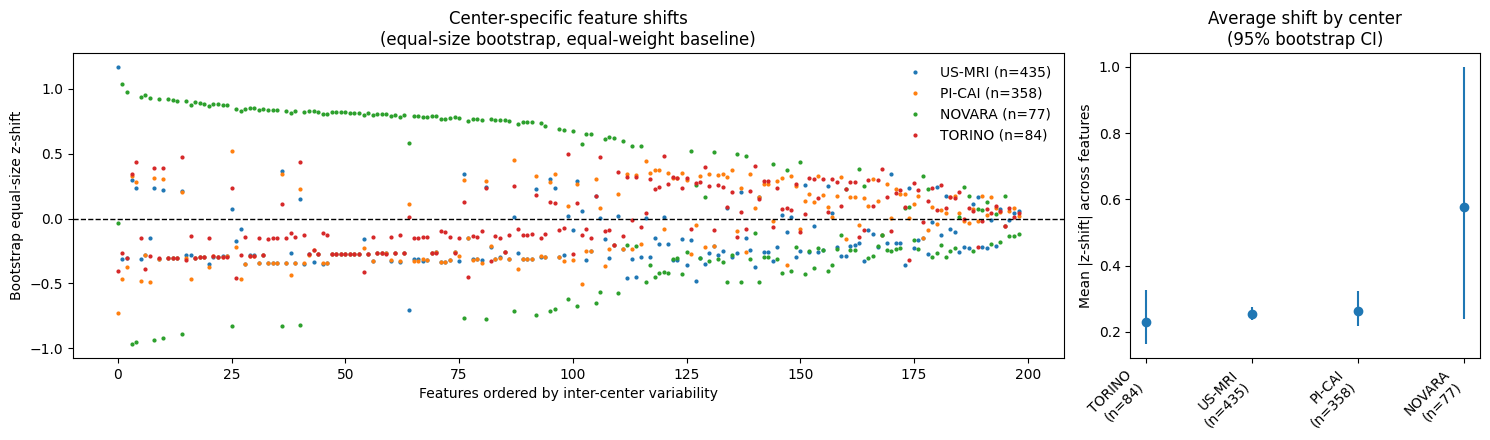

In [534]:


import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

B = 200
MIN_CENTER_SAMPLES = 50
RANDOM_STATE = 42

for i, (df_results_all, labels_all) in enumerate([
    [df_results_all.iloc[:,:], labels_all],
    # [df_results_all_pred, labels_all_pred]
]):
    rng = np.random.default_rng(RANDOM_STATE)

    # =====================================================
    # 0. allineamento e pulizia
    # =====================================================
    mask = labels_all["GG"] > -1
    X = df_results_all.loc[mask].copy()
    y = labels_all.loc[X.index].copy()

    X = X.select_dtypes(include=[np.number]).copy()
    X = X.replace([np.inf, -np.inf], np.nan)
    X = X.loc[:, X.notna().any(axis=0)]

    y = y.loc[X.index].copy()

    center_counts = y["center"].value_counts(dropna=True)
    valid_centers = center_counts[center_counts >= MIN_CENTER_SAMPLES].index.tolist()

    X = X.loc[y["center"].isin(valid_centers)].copy()
    y = y.loc[X.index].copy()

    centers = y["center"].dropna().unique()
    center_counts = y["center"].value_counts(dropna=True)
    N_common = int(center_counts.min())

    print(f"\nDataset {i}:")
    print("Centri tenuti:")
    print(center_counts.sort_values(ascending=False))
    print(f"N_common bootstrap = {N_common}")

    # =====================================================
    # 1. bootstrap center means a dimensione comune
    # =====================================================
    # per ogni centro e bootstrap: mean feature-wise
    boot_center_means = {center: [] for center in centers}

    for b in range(B):
        sampled_means = {}

        for center in centers:
            idx_center = y.index[y["center"] == center].to_numpy()

            boot_idx = rng.choice(idx_center, size=N_common, replace=True)
            Xb = X.loc[boot_idx]

            sampled_means[center] = Xb.mean(axis=0, skipna=True)

        # salva
        for center in centers:
            boot_center_means[center].append(sampled_means[center])

    # da liste -> dataframe per centro
    # ogni elemento sarà un DataFrame B x n_features
    boot_center_means_df = {
        center: pd.DataFrame(boot_center_means[center])
        for center in centers
    }

    # =====================================================
    # 2. baseline equal-weighted tra centri
    # =====================================================
    # mean_center_equal = media tra centri delle medie bootstrap
    # std_center_equal  = std globale su X originale (oppure pooled equal-weighted)
    #
    # qui uso std originale per stabilità, ma baseline della media equal-weighted
    std_all = X.std(axis=0, skipna=True).replace(0, np.nan)

    # media bootstrap per centro
    center_mean_of_means = {
        center: boot_center_means_df[center].mean(axis=0, skipna=True)
        for center in centers
    }
    center_mean_of_means_df = pd.DataFrame(center_mean_of_means).T

    mean_equal = center_mean_of_means_df.mean(axis=0, skipna=True)

    # =====================================================
    # 3. z-shift bootstrap per centro
    # =====================================================
    # z = (mean_boot_center - mean_equal) / std_all
    boot_z = {}
    for center in centers:
        zc = (boot_center_means_df[center] - mean_equal) / std_all
        zc = zc.replace([np.inf, -np.inf], np.nan)
        boot_z[center] = zc

    # media bootstrap dello z-shift
    z_df_mean = pd.DataFrame({
        center: boot_z[center].mean(axis=0, skipna=True)
        for center in centers
    }).T

    z_df_mean = z_df_mean.loc[:, z_df_mean.notna().any(axis=0)]

    # ordina feature per variabilità inter-centro
    order = z_df_mean.std(axis=0, skipna=True).sort_values(ascending=False).index
    z_df_mean = z_df_mean[order]

    # =====================================================
    # 4. summary bootstrap per centro
    # =====================================================
    # per ogni bootstrap: mean abs z across features
    summary_rows = []
    for center in centers:
        mean_abs_per_boot = boot_z[center].abs().mean(axis=1, skipna=True)

        summary_rows.append({
            "center": center,
            "mean_abs_z": mean_abs_per_boot.mean(),
            "median_abs_z": mean_abs_per_boot.median(),
            "ci_low": np.quantile(mean_abs_per_boot, 0.025),
            "ci_high": np.quantile(mean_abs_per_boot, 0.975),
            "n_cases": int(center_counts[center]),
        })

    center_summary = pd.DataFrame(summary_rows).sort_values("mean_abs_z", ascending=True)

    # =====================================================
    # 5. plot
    # =====================================================
    fig, ax = plt.subplots(
        1, 2, figsize=(15, 4.5),
        gridspec_kw={"width_ratios": [3.4, 1.2]}
    )

    # ---------- sinistra: feature-wise bootstrap mean z-shift ----------
    for center in z_df_mean.index:
        ax[0].plot(
            np.arange(z_df_mean.shape[1]),
            z_df_mean.loc[center].values,
            linestyle="",
            marker=".",
            markersize=4,
            label=f"{center} (n={center_counts[center]})"
        )

    ax[0].axhline(0.0, color="black", linestyle="--", linewidth=1)
    ax[0].set_xlabel("Features ordered by inter-center variability")
    ax[0].set_ylabel("Bootstrap equal-size z-shift")
    ax[0].set_title("Center-specific feature shifts\n(equal-size bootstrap, equal-weight baseline)")
    ax[0].legend(frameon=False)

    # ---------- destra: summary con CI ----------
    x = np.arange(len(center_summary))
    yv = center_summary["mean_abs_z"].values
    yerr_low = yv - center_summary["ci_low"].values
    yerr_high = center_summary["ci_high"].values - yv

    ax[1].errorbar(
        x, yv,
        yerr=[yerr_low, yerr_high],
        fmt="o"
    )
    ax[1].set_xticks(x)
    ax[1].set_xticklabels(
        [f"{c}\n(n={n})" for c, n in zip(center_summary["center"], center_summary["n_cases"])],
        rotation=45, ha="right"
    )
    ax[1].set_ylabel("Mean |z-shift| across features")
    ax[1].set_title("Average shift by center\n(95% bootstrap CI)")

    plt.tight_layout()

    TYPE = "gt" if i == 0 else "pred"
    plt.savefig(f"report_FINAL/feature_shift_summary_bootstrap_{TYPE}.pdf", bbox_inches="tight")
    plt.show()
    


In [535]:



import numpy as np
import pandas as pd
from sklearn.metrics import roc_auc_score
from scipy.stats import mannwhitneyu


MIN_SCANNER_SAMPLES = 20

# =========================================================
# 0. subset iniziale: solo US-MRI + PI-CAI
# =========================================================

mask_centers = labels_all["center"].isin(construction_centers)

X = df_results_all.loc[mask_centers].copy()
y = labels_all.loc[mask_centers].copy()

# tieni solo scanner con almeno N campioni
scanner_counts = y["scanner_c"].value_counts(dropna=True)
valid_scanners = scanner_counts[scanner_counts >= MIN_SCANNER_SAMPLES].index

mask_scanner = y["scanner_c"].isin(valid_scanners)
X = X.loc[mask_scanner].copy()
y = y.loc[mask_scanner].copy()

# pulizia feature numeriche
X = X.select_dtypes(include=[np.number]).copy()
X = X.replace([np.inf, -np.inf], np.nan)
X = X.loc[:, X.notna().any(axis=0)]

# riallinea y a X per sicurezza
y = y.loc[X.index].copy()

# binarizza target
y_bin = (y["GG"] >= 3).astype(int)

print("Scanner tenuti:")
print(y["scanner_c"].value_counts())
print(f"\nNumero scanner tenuti: {y['scanner_c'].nunique()}")
print(f"Numero casi tenuti: {len(y)}")

# =========================================================
# 1. metriche globali di "bruttezza" della feature
# =========================================================
abs_skew = X.skew(numeric_only=True).abs()

q01 = X.quantile(0.01)
q05 = X.quantile(0.05)
q25 = X.quantile(0.25)
q50 = X.quantile(0.50)
q75 = X.quantile(0.75)
q95 = X.quantile(0.95)
q99 = X.quantile(0.99)

iqr = q75 - q25

tail_ratio = ((q99 - q50).abs() / (iqr.abs() + 1e-12)).replace([np.inf, -np.inf], np.nan)
spread_ratio = ((q95.abs() + 1e-12) / (q05.abs() + 1e-12)).replace([np.inf, -np.inf], np.nan)
tail_median_ratio = ((q99.abs() + 1e-12) / (q50.abs() + 1e-12)).replace([np.inf, -np.inf], np.nan)
log_range = np.log10((q99.abs() + 1e-12) / (q01.abs() + 1e-12))

# shape/volume esplicite
shape_like = pd.Series(
    [("shape" in c.lower()) for c in X.columns],
    index=X.columns
)

volume_like_cols = [
    c for c in X.columns
    if any(k in c for k in ["MeshVolume", "VoxelVolume", "SurfaceArea"])
]

# correlazione con volume/shape
corr_with_shapevol = pd.Series(0.0, index=X.columns)

if len(volume_like_cols) > 0:
    corr_mat = X.corr().abs()
    for col in X.columns:
        refs = [v for v in volume_like_cols if v in corr_mat.columns and v != col]
        if len(refs) > 0:
            corr_with_shapevol[col] = corr_mat.loc[col, refs].max()
        else:
            corr_with_shapevol[col] = 0.0

# flag generali
flag_shape = shape_like
flag_skew = abs_skew > 3
flag_tail = tail_ratio > 8
flag_volcorr = corr_with_shapevol > 0.85

# flag "hard"
flag_spread = spread_ratio > 20
flag_tailmedian = tail_median_ratio > 15
flag_logrange = log_range > 1.5

# =========================================================
# 2. z-shift per scanner
# =========================================================
mean_all = X.mean(axis=0, skipna=True)
std_all = X.std(axis=0, skipna=True).replace(0, np.nan)

z_dict = {}
for scanner in y["scanner"].dropna().unique():
    mask = y["scanner"] == scanner
    if mask.sum() < MIN_SCANNER_SAMPLES:
        continue
    mean_scanner = X.loc[mask].mean(axis=0, skipna=True)
    z_dict[scanner] = (mean_scanner - mean_all) / std_all

z_df = pd.DataFrame(z_dict).T.replace([np.inf, -np.inf], np.nan)
z_df = z_df.loc[:, z_df.notna().any(axis=0)]

# =========================================================
# 3. ranking feature-wise
# =========================================================
rows = []

for col in X.columns:
    xx = X[col]
    valid = xx.notna() & y_bin.notna()
    if valid.sum() < 10:
        continue

    x0 = xx[(y_bin == 0) & valid]
    x1 = xx[(y_bin == 1) & valid]

    if len(x0) < 5 or len(x1) < 5:
        continue

    # p-value globale
    try:
        _, p = mannwhitneyu(x0, x1, alternative="two-sided")
    except Exception:
        p = np.nan

    # AUC univariata globale
    try:
        auc = roc_auc_score(y_bin[valid], xx[valid])
        auc_signal = abs(auc - 0.5)
    except Exception:
        auc = np.nan
        auc_signal = np.nan

    # shift tra scanner
    mean_abs_shift = z_df[col].abs().mean() if col in z_df.columns else np.nan
    max_abs_shift = z_df[col].abs().max() if col in z_df.columns else np.nan

    # direzione per scanner
    deltas_scanner = {}
    for scanner in y["scanner_c"].dropna().unique():
        m = (y["scanner_c"] == scanner) & valid

        # opzionale: richiedi almeno MIN_SCANNER_SAMPLES nel gruppo totale
        if m.sum() < MIN_SCANNER_SAMPLES:
            deltas_scanner[scanner] = np.nan
            continue

        x0s = xx[m & (y_bin == 0)]
        x1s = xx[m & (y_bin == 1)]

        if len(x0s) >= 3 and len(x1s) >= 3:
            deltas_scanner[scanner] = x1s.mean() - x0s.mean()
        else:
            deltas_scanner[scanner] = np.nan

    signs = pd.Series(deltas_scanner).dropna().apply(np.sign)
    sign_consistency = signs.nunique() == 1 if len(signs) > 0 else False

    rows.append({
        "feature": col,
        "p_GG": p,
        "auc": auc,
        "auc_signal": auc_signal,
        "mean_abs_shift": mean_abs_shift,
        "max_abs_shift": max_abs_shift,
        "sign_consistency": sign_consistency,
        "robust_score2": auc_signal / (mean_abs_shift + 1e-6),
        "abs_skew": abs_skew.get(col, np.nan),
        "tail_ratio": tail_ratio.get(col, np.nan),
        "spread_ratio": spread_ratio.get(col, np.nan),
        "tail_median_ratio": tail_median_ratio.get(col, np.nan),
        "log_range": log_range.get(col, np.nan),
        "corr_with_shapevol": corr_with_shapevol.get(col, np.nan),
        "flag_shape": flag_shape.get(col, False),
        "flag_skew": flag_skew.get(col, False),
        "flag_tail": flag_tail.get(col, False),
        "flag_volcorr": flag_volcorr.get(col, False),
        "flag_spread": flag_spread.get(col, False),
        "flag_tailmedian": flag_tailmedian.get(col, False),
        "flag_logrange": flag_logrange.get(col, False),
    })

robust_df2 = pd.DataFrame(rows)#.sort_values("robust_score2", ascending=False)



Scanner tenuti:
scanner_c
SIEMENS-Skyra-3.0-syngo MR E11-SIEMENS-Skyra-3.0-syngo MR E11                                                      202
SIEMENS-Skyra-3.0-RUMC-SIEMENS-Skyra-3.0-RUMC                                                                      162
SIEMENS-Skyra-3.0-syngo MR D13-SIEMENS-Skyra-3.0-syngo MR D13                                                      100
SIEMENS-Skyra-3.0-ZGT-SIEMENS-Skyra-3.0-ZGT                                                                         70
Philips Medical Systems-Ingenia-3.0-PCNN-Philips Medical Systems-Ingenia-3.0-PCNN                                   52
SIEMENS-Skyra_fit-3.0-syngo MR E11-SIEMENS-Skyra_fit-3.0-syngo MR E11                                               42
Siemens HealthCare GmbH-MAGNETOM Vida-3.0-syngo MR XA10-Siemens HealthCare GmbH-MAGNETOM Vida-3.0-syngo MR XA10     42
SIEMENS-TrioTim-3.0-RUMC-SIEMENS-TrioTim-3.0-RUMC                                                                   26
Name: count, dtype: in

<Axes: >

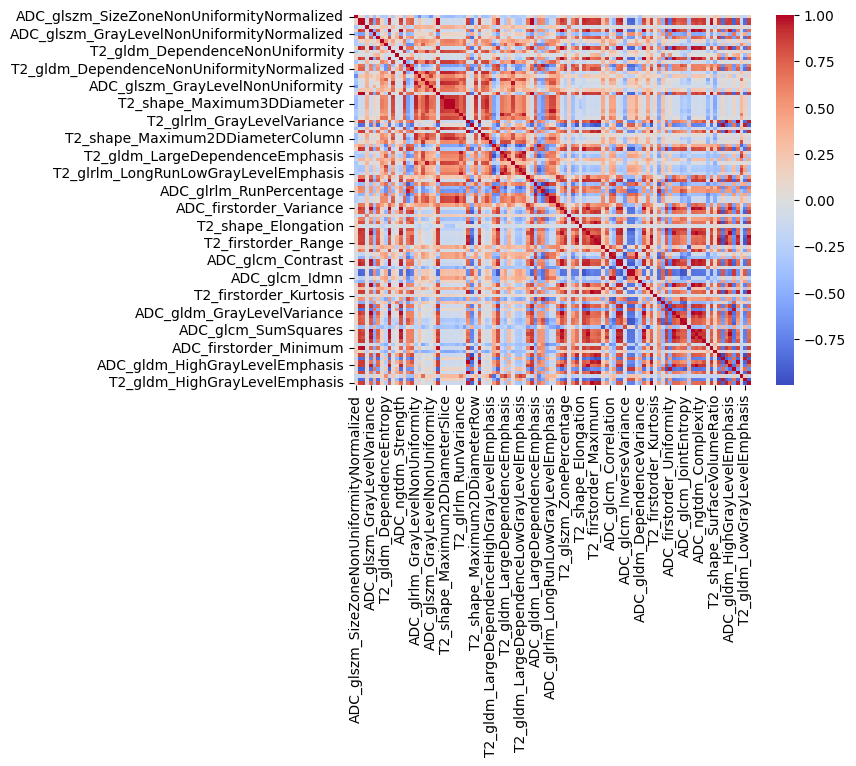

In [536]:
PENALTIES =   (#(robust_df2["sign_consistency"] == True) &
    #(robust_df2["mean_abs_shift"] < 0.40) &
    #(robust_df2["max_abs_shift"] < 0.60) &
    (robust_df2["auc_signal"] > 0.05) & 
    #(~robust_df2["flag_shape"]) &
    #(~robust_df2["flag_spread"]) &
    (~robust_df2["flag_tailmedian"]) &
    (~robust_df2["flag_logrange"]))
# =========================================================
# 4. candidate robuste
# =========================================================
cand = robust_df2[ PENALTIES
].copy()

cand["penalty"] = (
    0.0 * cand["flag_skew"].astype(int) +
    0.0 * cand["flag_tail"].astype(int) +
    0.0 * cand["flag_volcorr"].astype(int)
)

cand["score_final"] = cand["robust_score2"] - cand["penalty"]

cand = cand.sort_values(
    ["score_final", "auc_signal", "mean_abs_shift"],
    ascending=[False, False, True]
)
import seaborn as sns
sns.heatmap(df_results_all[cand['feature'].values].corr(), cmap = 'coolwarm')


Candidate features in cand: 106
Available candidate features: 106
Numeric ranked features: 106

SEL2: top-ranked greedy decorrelated features

Selected features (10):
['ADC_glszm_SizeZoneNonUniformityNormalized', 'ADC_firstorder_Maximum', 'ADC_firstorder_Mean', 'ADC_glszm_GrayLevelVariance', 'T2_glcm_SumEntropy', 'T2_glszm_ZoneEntropy', 'T2_gldm_DependenceNonUniformity', 'ADC_ngtdm_Coarseness', 'ADC_glrlm_RunLengthNonUniformityNormalized', 'ADC_glszm_GrayLevelNonUniformity']


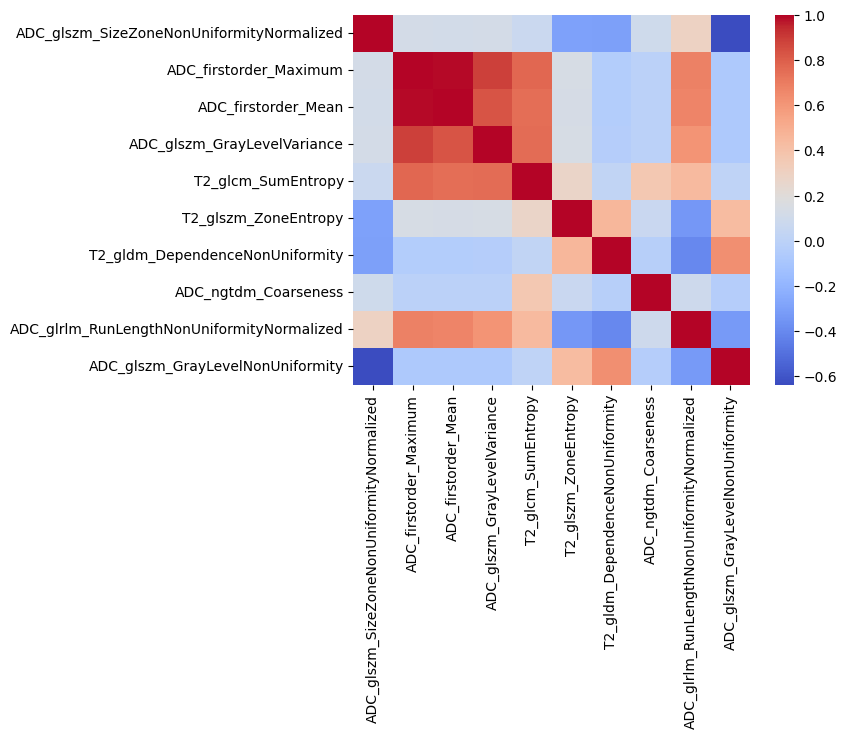

In [538]:
# =========================================================
# PREP
# =========================================================

cand_features = cand["feature"].dropna().tolist()

available_cand_features = [
    f for f in cand_features
    if f in df_results_all.columns
]

df_results_all = df_results_all[available_cand_features]

center_aligned = labels_all.loc[df_results_all.index, "center"]
mask_construction = center_aligned.isin(construction_centers)

X_corr_fit = (
    df_results_all
    .loc[mask_construction]
    .select_dtypes(include=[np.number])
    .copy()
)

corr = X_corr_fit.corr().abs()

ranked_features = [
    f for f in available_cand_features
    if f in X_corr_fit.columns
]

print(f"Candidate features in cand: {len(cand_features)}")
print(f"Available candidate features: {len(available_cand_features)}")
print(f"Numeric ranked features: {len(ranked_features)}")

if len(ranked_features) < N_FEATURES:
    raise ValueError(
        f"Only {len(ranked_features)} numeric candidate features available, "
        f"but N_FEATURES={N_FEATURES}. Lower N_FEATURES or fix cand/features."
    )

# =========================================================
# SEL1
# =========================================================

if FEATURE_SELECTION_MODE == "SEL1":

    n_high = (corr > CORR_THR).sum() - 1

    ranked_by_score = (
        pd.DataFrame({
            "feature": ranked_features,
            "n_high_corr": [n_high[f] for f in ranked_features],
            "cand_rank": range(len(ranked_features)),
        })
        .sort_values(["n_high_corr", "cand_rank"], ascending=[True, True])
    )

    cols_selected = ranked_by_score["feature"].head(N_FEATURES).tolist()

    print("\nSEL1: top low-hub features")

# =========================================================
# SEL2
# =========================================================

elif FEATURE_SELECTION_MODE == "SEL2":

    cols_selected = []

    for col in ranked_features:
        if len(cols_selected) == 0:
            cols_selected.append(col)
        else:
            max_corr_with_selected = corr.loc[col, cols_selected].max()

            if max_corr_with_selected <= CORR_THR:
                cols_selected.append(col)

        if len(cols_selected) >= N_FEATURES:
            break

    # fallback: se il decorrelation pruning è troppo severo,
    # riempi con le migliori feature rimanenti da cand
    if len(cols_selected) < N_FEATURES:
        print(
            f"⚠️ SEL2 selected only {len(cols_selected)} decorrelated features. "
            "Filling with next best cand features."
        )

        for col in ranked_features:
            if col not in cols_selected:
                cols_selected.append(col)

            if len(cols_selected) >= N_FEATURES:
                break

    print("\nSEL2: top-ranked greedy decorrelated features")

else:
    raise ValueError(f"Unknown FEATURE_SELECTION_MODE: {FEATURE_SELECTION_MODE}")

# =========================================================
# FINAL
# =========================================================

if len(cols_selected) != N_FEATURES:
    raise ValueError(f"Expected {N_FEATURES} features, got {len(cols_selected)}")

print(f"\nSelected features ({len(cols_selected)}):")
print(cols_selected)

sns.heatmap(
    df_results_all[cols_selected].corr(),
    cmap="coolwarm"
)

df_results_all = df_results_all[cols_selected]

## 8. Construction / external split and target

Rows with missing values are dropped, PSA density is added, and the data are split into the construction set (US-MRI + PI-CAI) and the external sets (NOVARA, TORINO). The binary target is `GG >= 3`.

In [539]:
if USE_PSA == True:
    df_results_all['psa_density'] = labels_all['psa_density']
else:
    df_results_all.drop(columns=['psa_density'], inplace=True, errors='ignore')

In [540]:
labels_all = labels_all.transpose()[df_results_all.dropna().index].transpose()
images_all = images_all.transpose()[df_results_all.dropna().index].transpose()
df_results_all = df_results_all.dropna().reset_index(drop=True)
mask_centers = labels_all["center"].isin(construction_centers)

In [542]:
labels_all['center'].unique()

array(['US-MRI', 'PI-CAI', 'NOVARA', 'TORINO'], dtype=object)

In [543]:
X_constr = df_results_all.loc[mask_centers.values].copy()
y_constr = labels_all.loc[mask_centers.values].copy()



X_val = df_results_all[((labels_all['center']=='NOVARA')| (labels_all['center']=='TORINO')).values]
y_val = labels_all[((labels_all['center']=='NOVARA')| (labels_all['center']=='TORINO')).values]

In [545]:
X_constr.reset_index(drop=True, inplace=True)
y_constr.reset_index(drop=True, inplace=True)

In [547]:
X_test = X_constr.copy()
y_test = y_constr.copy()

In [549]:
I = 0

#y_constr = y_constr.reset_index()

strats = ['with', 'without']

strat = strats[I]

if strat == 'without':
    
    X_constr = X_constr[(y_constr['GG']!=3) & (y_constr['GG']!=3)  ]
    y_constr = y_constr[(y_constr['GG']!=3) & (y_constr['GG']!=3)  ]
    
y_constr = (y_constr['GG'] >= 3).astype(int)
y_constr = y_constr.reset_index(drop=True)
y_val = (y_val['GG'] >= 3).astype(int)
y_test = (y_test['GG'] >= 3).astype(int)

feature_names_clean = X_constr.columns

labels_val = labels_all[(labels_all['center']=='NOVARA') | (labels_all['center']=='TORINO')]


IDX_NOV = len(labels_val[labels_val['center']=='NOVARA'])

#IDX_NOV = 77

y_val_tot = y_val
X_val_tot = X_val

X_val_novara = X_val.iloc[:IDX_NOV]
y_val_novara = y_val.iloc[:IDX_NOV]
labels_novara = labels_val.iloc[:IDX_NOV]

X_val_torino = X_val.iloc[IDX_NOV: ]
y_val_torino = y_val.iloc[IDX_NOV: ]
labels_torino = labels_val.iloc[IDX_NOV: ]

labels_nov = labels_val[:IDX_NOV]
labels_tor = labels_val[IDX_NOV:]

y_constr = y_constr.reset_index().drop(columns = 'index')

## 9. Classifier definition

The search space is reduced to a single configuration: `StandardScaler` → `RFE` (keeping all features) → `LogisticRegression`, with `C` tuned by Optuna inside the cross-validation.

In [550]:
# STEP 4: DEFINIZIONE COMPONENTI PIPELINE - RIDOTTO <1000 COMBINAZIONI
print("\n4️⃣ DEFINIZIONE COMPONENTI PIPELINE")


scalers_options = {
   #'none': None,                             # nessuna scaling
   # 'minmax': MinMaxScaler(),                    # [0, 1]
    'standard': StandardScaler(),                # media 0, varianza 1
   # 'quantile_uniform': QuantileTransformer(output_distribution='uniform', n_quantiles=20),   # mappa ai quantili uniformi
  #  'quantile_gaussian': QuantileTransformer(output_distribution='normal', n_quantiles=20),   # mappa a distribuzione normale
   # 'yeo_johnson': PowerTransformer(method='yeo-johnson', standardize=True),                    # stabilizza varianza, simile a Box-Cox
   # 'robust': RobustScaler(),                    # basato su mediane e IQR (percentili 25–75)
}


imbalance_options = {
    'none': None,                               # Baseline current
  #  'smote': SMOTE(random_state=42, k_neighbors=3),              # Standard SMOTE
 #   'adasyn': ADASYN(random_state=42),                           # Adaptive
 #   'smotetomek': SMOTETomek(random_state=42),                   # SMOTE + cleaning
}

K = 10  # FISSO: poche feature per interpretabilità clinica



feature_selectors_options = {
    # STATISTICI UNIVARIATI (più performanti)
    #'kbest_f': SelectKBest(f_classif, k=K),                    # F-test ANOVA (current baseline)
    #'kbest_mi': SelectKBest(mutual_info_classif, k=K),         # Mutual Information
    
    # CLUSTERING-BASED (rimozione ridondanza) - quelli che già avevi
    #'affinity_5': AffinityPropagationSelector(n_features=K),   # Current baseline
    #f'apcorr_f_{K}': AffinityPropagationSelector2(n_features=K, score_func='f', corr='pearson', pref_quantile=0.50),
    #f'apcorr_mi_{K}': AffinityPropagationSelector2(n_features=K, score_func='mi', corr='pearson', pref_quantile=0.50),
    
    # RECURSIVE FEATURE ELIMINATION (model-based) - solo il migliore
  #  'rfe_lr': RFE(LogisticRegression(random_state=42, max_iter=1000, C=1.0), n_features_to_select=K),
    'rfe_lr_5': RFE(
    LogisticRegression(random_state=42, max_iter=1000),
    n_features_to_select=df_results_all.columns.values.shape[0]
),

#    'rfe_lr_4': RFE(
#    LogisticRegression(random_state=42, max_iter=1000),
#    n_features_to_select=4
#),
    #'rfe_lr_10': RFE(
    #ogisticRegression(random_state=42, max_iter=1000),
    #n_features_to_select=10
#),
}



classifiers_options = {
    # === LOGISTIC REGRESSION VARIANTS (tutti lineari!) ===
    
    # L1 "lasso" (sparse, auto feature selection)
    #'logistic_l1': LogisticRegression(
    #    solver='liblinear', penalty='l1', C=0.5,
    #    class_weight=None, max_iter=4000, random_state=42
    
    #),
    
    # SGD logistic (efficiente)
    #'sgd_logistic': SGDClassifier(
    #    loss='log_loss', penalty='elasticnet', alpha=1e-4, l1_ratio=0.15,
    #    class_weight=None, max_iter=2000, tol=1e-3, random_state=42
    #),
    
    
    'logistic_base': LogisticRegression(random_state=42, max_iter=1000, class_weight=None),
#  'svm_linear': SVC(kernel='linear', probability=True, random_state=42, class_weight=None),  # SVM LINEARE!
    
    # L2 "ridge" stabile 
    #'logistic_l2': LogisticRegression(
    #    solver='lbfgs', penalty='l2', C=1.0, 
    #    class_weight=None, max_iter=4000, random_state=42
    #),
    
    # Elastic Net (selezione soft + stabilità)
    #'logistic_elastic': LogisticRegression(
    #    solver='saga', penalty='elasticnet', l1_ratio=0.2, C=1.0,
    #    class_weight=None, max_iter=4000, random_state=42
    #),
    #'naive_bayes': GaussianNB(),  # Interpretabile ma non lineare (mantienilo se vuoi)
}

param_grid = {
    # === LOGISTIC REGRESSION VARIANTS ===
    'logistic_base': {
        'clf__C': [0.1, 0.5, 1.0, 2.0]
    },
    'logistic_l2': {
        'clf__C': [0.1, 0.3, 1, 3]
    },
    'logistic_elastic': {
        'clf__C': [0.1, 0.5, 1, 2],
        'clf__l1_ratio': [0.0, 0.2, 0.5]  # 0.0 = ridge
    },
    'logistic_l1': {
        'clf__C': [0.1, 0.3, 1, 3]
    },
    'sgd_logistic': {
        'clf__alpha': [1e-5, 1e-4, 5e-4],
        'clf__l1_ratio': [0.1, 0.15, 0.3]
    },
    
    # === ALTRI CLASSIFICATORI ===
    'svm_linear': {
        'clf__C': [0.1, 1.0, 10.0]
    },
}

print(f"\n📊 OPZIONI DISPONIBILI:")
print(f"Scalers ({len(scalers_options)}): {list(scalers_options.keys())}")
print(f"Imbalance methods ({len(imbalance_options)}): {list(imbalance_options.keys())}")
print(f"Feature selectors ({len(feature_selectors_options)}): {list(feature_selectors_options.keys())}")
print(f"Classifiers ({len(classifiers_options)}): {list(classifiers_options.keys())}")

print(f"\n🧮 INTERPRETABILITÀ:")
print(f"✅ MODELLI LINEARI (combinazioni lineari): logistic_*, sgd_logistic, svm_linear")
print(f"⚠️  INTERPRETABILE ma non lineare: naive_bayes (probabilità bayesiane)")
print(f"📊 Tutti i coefficienti sono estraibili e interpretabili!")

total_combinations = len(scalers_options) * len(imbalance_options) * len(feature_selectors_options) * len(classifiers_options)
print(f"\n🎯 Totale combinazioni da testare: {total_combinations}")

# STEP 5: FUNZIONE DI VALUTAZIONE CON CV SUL CONSTRUCTION SET
print("\n5️⃣ SETUP CROSS-VALIDATION")




4️⃣ DEFINIZIONE COMPONENTI PIPELINE

📊 OPZIONI DISPONIBILI:
Scalers (1): ['standard']
Imbalance methods (1): ['none']
Feature selectors (1): ['rfe_lr_5']
Classifiers (1): ['logistic_base']

🧮 INTERPRETABILITÀ:
✅ MODELLI LINEARI (combinazioni lineari): logistic_*, sgd_logistic, svm_linear
⚠️  INTERPRETABILE ma non lineare: naive_bayes (probabilità bayesiane)
📊 Tutti i coefficienti sono estraibili e interpretabili!

🎯 Totale combinazioni da testare: 1

5️⃣ SETUP CROSS-VALIDATION


## 10. Training (nested cross-validation on the construction set)

Each configuration is evaluated with 5 outer folds; hyperparameters are tuned in the inner loop (Optuna, up to 100 trials with early stopping). The results table is saved to `final_pipe_train_on_gt_psa.csv`.

In [551]:
X_constr = X_constr.astype(np.float32)

In [552]:
y_constr = y_constr.astype(np.float32)

In [553]:
X_constr = X_constr.astype(float)


optuna.logging.set_verbosity(optuna.logging.ERROR)

cv_results_corrected = []
combination_count = 0

start_time = pd.Timestamp.now()

for scaler_name in scalers_options.keys():
    for imbalance_name in imbalance_options.keys():
        for selector_name in feature_selectors_options.keys():
            for classifier_name in classifiers_options.keys():

                combination_count += 1

                print(
                    f"Combinazione {combination_count:3d}/{total_combinations}: "
                    f"{scaler_name:<8} + {imbalance_name:<10} + "
                    f"{selector_name:<8} + {classifier_name:<8}",
                    end=" "
                )

                try:
                        #evaluate_pipeline_lodo_with_threshold
                        #evaluate_pipeline_construction_cv_with_threshold
                    result = evaluate_pipeline_construction_cv_with_threshold(
                        scaler_name,
                        imbalance_name,
                        selector_name,
                        classifier_name,
                        X_constr=X_constr,
                        y_constr=y_constr,
                        #IDX_US=IDX_US,
                        use_youden=True,
                        use_tprev=True,
                        n_trials=100,
                        timeout=30,
                        n_jobs_optuna=1,
                        print_every=10,
                        early_stop_patience=10,
                        early_stop_min_delta=1e-3
                    )

                    cv_results_corrected.append(result)

                    msg = f"AUC: {result['median_auc_cv']:.3f}±{result['std_auc_cv']:.3f}"

                    if 'median_youden_cv' in result:
                        msg += (
                            f" | J(train): {result['median_youden_cv']:.3f}"
                            f" | t_Y: {result['median_threshold_cv']:.3f}±{result['std_threshold_cv']:.3f}"
                        )

                    if 'median_threshold_prev_cv' in result:
                        msg += (
                            f" | t_prev: {result['median_threshold_prev_cv']:.3f}±{result['std_threshold_prev_cv']:.3f}"
                        )

                    print(msg)

                except Exception as e:
                    print(f"❌ Errore: {str(e)[:60]}...")
                    continue


end_time = pd.Timestamp.now()
duration = (end_time - start_time).total_seconds()

print("\n✅ GRID SEARCH CORRETTO COMPLETATO!")
print(f"   • Durata: {duration:.1f} secondi")
print(f"   • Combinazioni testate: {len(cv_results_corrected)}")
print("   • Metodologia: LODO + threshold TRAIN-derived (Youden + t_prev)")

Combinazione   1/1: standard + none       + rfe_lr_5 + logistic_base    Outer fold 1/5 | train=551 | val=138
      trial  10 | current=0.7432 | best=0.7497 | best_trial=4
      early stop at trial 15: no improvement > 0.001 for 10 trials
      best outer-fold-1 inner-CV AUC = 0.7497 | best params = {'C': 0.04207988669606637}
   Outer fold 2/5 | train=551 | val=138
      trial  10 | current=0.7167 | best=0.7211 | best_trial=4
      trial  20 | current=0.7228 | best=0.7239 | best_trial=11
      early stop at trial 21: no improvement > 0.001 for 10 trials
      best outer-fold-2 inner-CV AUC = 0.7239 | best params = {'C': 0.16481177259910382}
   Outer fold 3/5 | train=551 | val=138
      trial  10 | current=0.7453 | best=0.7492 | best_trial=4
      early stop at trial 15: no improvement > 0.001 for 10 trials
      best outer-fold-3 inner-CV AUC = 0.7502 | best params = {'C': 0.06678114786528214}
   Outer fold 4/5 | train=551 | val=138
      trial  10 | current=0.7402 | best=0.7427 | best_

In [554]:

cv_results_corrected_df = pd.DataFrame(cv_results_corrected)
cv_results_corrected_df.to_csv("final_pipe_train_on_gt_psa.csv", index=False)


## 11. Best configuration and thresholds

The best configuration is selected from the cross-validation table, and the median thresholds across outer folds are collected.

In [555]:
K_BEST_COMBINATION = 0


best_results = cv_results_corrected_df.sort_values(['std_auc_cv'], ascending=True)


# Migliore combinazione
best_combination_corrected = best_results.iloc[K_BEST_COMBINATION ]
print(f"\n🎯 MIGLIORE COMBINAZIONE:")
print(f"   • Scaler: {best_combination_corrected['scaler']}")
print(f"   • Imbalance: {best_combination_corrected['imbalance']}")
print(f"   • Selector: {best_combination_corrected['selector']} (MRMR)")
print(f"   • Classifier: {best_combination_corrected['classifier']}")

print(f"\n📈 PERFORMANCE MIGLIORE COMBINAZIONE (CV):")
print(f"   • Youden Index: {best_combination_corrected['median_youden_cv']:.4f} ± {best_combination_corrected['std_youden_cv']:.4f}")
print(f"   • AUC: {best_combination_corrected['median_auc_cv']:.4f} ± {best_combination_corrected['std_auc_cv']:.4f}")
print(f"   • Threshold: {best_combination_corrected['median_threshold_cv']:.3f} ± {best_combination_corrected['std_threshold_cv']:.3f}")




🎯 MIGLIORE COMBINAZIONE:
   • Scaler: standard
   • Imbalance: none
   • Selector: rfe_lr_5 (MRMR)
   • Classifier: logistic_base

📈 PERFORMANCE MIGLIORE COMBINAZIONE (CV):
   • Youden Index: 0.3900 ± 0.0200
   • AUC: 0.7330 ± 0.0467
   • Threshold: 0.266 ± 0.024


In [556]:
threshold_cols = [
    'scaler', 'imbalance', 'selector', 'classifier',
    'median_threshold_cv', 
    'median_threshold_prev_cv', 
    'median_threshold_f2_cv', 
    'median_threshold_sens90_cv', 
    'median_threshold_spec90_cv', 
    'median_threshold_topleft_cv', 
]

df_thresholds = best_results[threshold_cols].copy()

In [557]:
# --- Salva come variabili principali (mantiene compatibilità col codice esistente) ---
optimal_threshold_corrected = best_results['median_threshold_spec90_cv'].values[K_BEST_COMBINATION ] #t_youden#t_prev # default (mantiene il tuo nome)

print("\n✅ Threshold multipli calcolati — pronto per test cross-site.")



✅ Threshold multipli calcolati — pronto per test cross-site.


## 12. Rebuild the best pipeline and fit it on the full construction set

The pipeline is rebuilt with the recommended hyperparameters and fitted on the whole construction set. Coefficients of this single logistic regression are printed for inspection. The deployed classifier is then fitted as the scanner-wise mixture of bootstrap experts; thresholds are recomputed on the full construction set, and the bootstrap coefficients are averaged to obtain the feature importance used in FIG 3. The trained classifier is saved with `joblib`.

In [558]:
# =============================================================================
# RICOSTRUZIONE PIPELINE E VARIABILI DALLA MIGLIORE COMBINAZIONE
# =============================================================================
from imblearn.pipeline import Pipeline
from sklearn.base import clone
import ast

print("🔧 RICOSTRUZIONE PIPELINE E VARIABILI DALLA MIGLIORE COMBINAZIONE")

# -------------------------------------------------
# 1) Info migliore combinazione
# -------------------------------------------------
print(f"\n📊 Migliore combinazione:")
print(f"   • Scaler: {best_combination_corrected['scaler']}")
print(f"   • Imbalance: {best_combination_corrected['imbalance']}")
print(f"   • Selector: {best_combination_corrected['selector']}")
print(f"   • Classifier: {best_combination_corrected['classifier']}")

# -------------------------------------------------
# 2) Ricostruzione pipeline step by step
# -------------------------------------------------
steps_corrected = []

# Scaler
scaler_name = best_combination_corrected['scaler']
scaler_obj = scalers_options[scaler_name]

if scaler_name != 'none' and scaler_obj is not None:
    steps_corrected.append(('scaler', clone(scaler_obj)))
else:
    print("ℹ️  Nessuno scaler aggiunto")

# Imbalance
imbalance_name = best_combination_corrected['imbalance']
imbalance_obj = imbalance_options[imbalance_name]

if imbalance_name != 'none' and imbalance_obj is not None:
    steps_corrected.append(('imbalance', clone(imbalance_obj)))
else:
    print("ℹ️  Nessun metodo di imbalance aggiunto")

# Selector
selector_name = best_combination_corrected['selector']
selector_obj = feature_selectors_options[selector_name]

if selector_name != 'none' and selector_obj is not None:
    steps_corrected.append(('selector', clone(selector_obj)))
else:
    print("ℹ️  Nessun feature selector aggiunto")

# Classifier
classifier_name = best_combination_corrected['classifier']
classifier_obj = classifiers_options[classifier_name]

if classifier_obj is None:
    raise ValueError(f"❌ Il classifier '{classifier_name}' è None, impossibile costruire la pipeline.")

steps_corrected.append(('classifier', clone(classifier_obj)))

# Crea pipeline
best_pipeline_corrected = Pipeline(steps_corrected)

print(f"\n✅ Pipeline ricostruita con {len(steps_corrected)} step")
print("   Step della pipeline:")
for step_name, step_obj in steps_corrected:
    print(f"   - {step_name}: {step_obj.__class__.__name__}")

# -------------------------------------------------
# 3) Recupero e parsing iperparametri consigliati
# -------------------------------------------------
best_params = best_combination_corrected.get('recommended_params', {})

if isinstance(best_params, str):
    best_params = best_params.strip()
    if best_params == "":
        best_params = {}
    else:
        try:
            best_params = ast.literal_eval(best_params)
        except Exception as e:
            raise ValueError(
                f"Impossibile convertire recommended_params da stringa a dict.\n"
                f"Valore trovato: {best_params}\nErrore: {e}"
            )

if best_params is None:
    best_params = {}

if not isinstance(best_params, dict):
    raise TypeError(
        f"recommended_params deve essere un dict o una stringa convertibile a dict, "
        f"ma è di tipo {type(best_params)} con valore: {best_params}"
    )

print(f"\n🔍 recommended_params parsato: {best_params}")

# -------------------------------------------------
# 4) Applica i parametri
# -------------------------------------------------
if best_params:
    # Se le chiavi NON hanno già il prefisso, assumiamo siano del classifier
    if all('__' not in k for k in best_params.keys()):
        params_to_set = {f'classifier__{k}': v for k, v in best_params.items()}
    else:
        params_to_set = best_params.copy()

    best_pipeline_corrected.set_params(**params_to_set)
    print(f"⚙️  Parametri impostati: {params_to_set}")
else:
    print("⚠️  Nessun set di iperparametri specifico trovato (uso valori di default)")

# -------------------------------------------------
# 5) Stampa finale
# -------------------------------------------------
print("\n📦 Pipeline finale pronta:")
print(best_pipeline_corrected)

🔧 RICOSTRUZIONE PIPELINE E VARIABILI DALLA MIGLIORE COMBINAZIONE

📊 Migliore combinazione:
   • Scaler: standard
   • Imbalance: none
   • Selector: rfe_lr_5
   • Classifier: logistic_base
ℹ️  Nessun metodo di imbalance aggiunto

✅ Pipeline ricostruita con 3 step
   Step della pipeline:
   - scaler: StandardScaler
   - selector: RFE
   - classifier: LogisticRegression

🔍 recommended_params parsato: {'C': 0.3148911647956863}
⚙️  Parametri impostati: {'classifier__C': 0.3148911647956863}

📦 Pipeline finale pronta:
Pipeline(steps=[('scaler', StandardScaler()),
                ('selector',
                 RFE(estimator=LogisticRegression(max_iter=1000,
                                                  random_state=42),
                     n_features_to_select=11)),
                ('classifier',
                 LogisticRegression(C=0.3148911647956863, max_iter=1000,
                                    random_state=42))])


In [560]:

# Fit della pipeline sul construction set

best_pipeline_corrected.fit(X_constr[:], y_constr[:])

# 4. RICALCOLO threshold ottimale su TUTTO il construction set
y_constr_proba = best_pipeline_corrected.predict_proba(X_constr[:])[:, 1]


# =============================================================================
# 5. ESTRAZIONE COEFFICIENTI DELLA REGRESSIONE LOGISTICA
# =============================================================================
print(f"\n5️⃣ ESTRAZIONE COEFFICIENTI REGRESSIONE LOGISTICA")

# Accesso al classificatore dalla pipeline
classifier_corrected = best_pipeline_corrected.named_steps['classifier']

# Verifica che sia una regressione logistica
if hasattr(classifier_corrected, 'coef_'):
    coefficients_corrected = classifier_corrected.coef_[0]  # Coefficienti per classe 1
    intercept_corrected = classifier_corrected.intercept_[0]
    
    # Nomi delle feature selezionate (dopo scaling e feature selection)
    feature_selector_corrected = best_pipeline_corrected.named_steps['selector']
    selected_features_mask_corrected = feature_selector_corrected.get_support(indices=False)
    selected_feature_names_corrected = X_constr[:].columns[selected_features_mask_corrected]
    
    print(f"   ✅ Coefficienti estratti con successo!")
    print(f"   • Numero feature selezionate: {len(selected_feature_names_corrected)}")
    print(f"   • Intercetta: {intercept_corrected:.4f}")
    
    # Creare DataFrame per analisi coefficienti
    feature_importance_df = pd.DataFrame({
        'Feature': selected_feature_names_corrected,
        'Coefficient': coefficients_corrected,
        'Abs_Coefficient': np.abs(coefficients_corrected)
    }).sort_values('Abs_Coefficient', ascending=False)
    
    print(f"\n   📊 TOP 5 FEATURE PIÙ IMPORTANTI:")
    for i, (_, row) in enumerate(feature_importance_df.iterrows()):
        coeff_type = "↗️ Positivo" if row['Coefficient'] > 0 else "↘️ Negativo"
        print(f"      {i+1}. {row['Feature']:<35} = {row['Coefficient']:+.4f} ({coeff_type})")
        
else:
    print(f"   ⚠️ Il classificatore non ha coefficienti interpretatili")
    print(f"   • Tipo classificatore: {type(classifier_corrected).__name__}")
    coefficients_corrected = None




5️⃣ ESTRAZIONE COEFFICIENTI REGRESSIONE LOGISTICA
   ✅ Coefficienti estratti con successo!
   • Numero feature selezionate: 11
   • Intercetta: -1.1677

   📊 TOP 5 FEATURE PIÙ IMPORTANTI:
      1. psa_density                         = +0.6720 (↗️ Positivo)
      2. ADC_ngtdm_Coarseness                = -0.6537 (↘️ Negativo)
      3. ADC_glrlm_RunLengthNonUniformityNormalized = -0.3321 (↘️ Negativo)
      4. ADC_glszm_GrayLevelNonUniformity    = +0.2876 (↗️ Positivo)
      5. ADC_firstorder_Maximum              = -0.2216 (↘️ Negativo)
      6. ADC_firstorder_Mean                 = +0.1729 (↗️ Positivo)
      7. T2_glszm_ZoneEntropy                = -0.1231 (↘️ Negativo)
      8. ADC_glszm_GrayLevelVariance         = +0.1227 (↗️ Positivo)
      9. T2_glcm_SumEntropy                  = -0.1150 (↘️ Negativo)
      10. T2_gldm_DependenceNonUniformity     = -0.0796 (↘️ Negativo)
      11. ADC_glszm_SizeZoneNonUniformityNormalized = -0.0495 (↘️ Negativo)


In [561]:

# =============================================================================
# 1. PREPARAZIONE DATI CONSTRUCTION SET
# =============================================================================
labels_constr = labels_all.loc[X_constr.index].copy()
y_constr = (labels_constr["GG"] >= 3).astype(int)

base_pipeline_corrected = clone(best_pipeline_corrected)

best_pipeline_corrected = ScannerMixtureOfExpertsBootstrap(
    base_pipeline=base_pipeline_corrected,
    scanner_labels=labels_constr["scanner_c"],
    min_samples=50,
    n_bootstrap=20,
    bootstrap_size=70,
    balanced_bootstrap=True,
    random_state=42,
    min_minority_for_smote=6,
)

# =============================================================================
# 2. FIT DELLA PIPELINE SUL CONSTRUCTION SET
# =============================================================================
best_pipeline_corrected.fit(X_constr[:], y_constr[:])

# =============================================================================
# 3. RICALCOLO PROBABILITÀ SU TUTTO IL CONSTRUCTION SET
# =============================================================================
print(f"\n3️⃣ PREDIZIONE MIXTURE OF EXPERTS BOOTSTRAP SUL CONSTRUCTION SET")

y_constr_proba = best_pipeline_corrected.predict_proba(X_constr[:])[:, 1]
df_expert_proba_constr = best_pipeline_corrected.get_expert_proba_df(X_constr[:])

print(f"   ✅ Predizioni MOE bootstrap calcolate con successo!")
print(f"   • Shape matrice expert-proba: {df_expert_proba_constr.shape}")

# =============================================================================
# 4. RICALCOLO THRESHOLDS SU TUTTO IL CONSTRUCTION SET
# =============================================================================
print(f"\n4️⃣ RICALCOLO THRESHOLDS SU TUTTO IL CONSTRUCTION SET")

thr_dict = compute_thresholds(y_constr, y_constr_proba)

optimal_threshold_corrected = thr_dict["youden"]
optimal_threshold_prev_corrected = thr_dict["prev"]
optimal_threshold_f2_corrected = thr_dict["f2"]
optimal_threshold_sens90_corrected = thr_dict["sens90"]
optimal_threshold_spec90_corrected = thr_dict["spec90"]
optimal_threshold_topleft_corrected = thr_dict["topleft"]

fpr = thr_dict["fpr"]
tpr = thr_dict["tpr"]
thresholds = thr_dict["roc_thresholds"]

print(f"   ✅ Youden   threshold: {optimal_threshold_corrected:.4f}")
print(f"   ✅ Prev     threshold: {optimal_threshold_prev_corrected:.4f}")
print(f"   ✅ F2       threshold: {optimal_threshold_f2_corrected:.4f}")
print(f"   ✅ Sens90   threshold: {optimal_threshold_sens90_corrected:.4f}")
print(f"   ✅ Spec90   threshold: {optimal_threshold_spec90_corrected:.4f}")
print(f"   ✅ TopLeft  threshold: {optimal_threshold_topleft_corrected:.4f}")

# opzionale: contenitore con nomi simili a quelli CV
threshold_summary_corrected = {
    "median_threshold_cv": optimal_threshold_corrected,
    "median_threshold_prev_cv": optimal_threshold_prev_corrected,
    "median_threshold_f2_cv": optimal_threshold_f2_corrected,
    "median_threshold_sens90_cv": optimal_threshold_sens90_corrected,
    "median_threshold_spec90_cv": optimal_threshold_spec90_corrected,
    "median_threshold_topleft_cv": optimal_threshold_topleft_corrected,
}

# =============================================================================
# 5. ESTRAZIONE COEFFICIENTI DELLA REGRESSIONE LOGISTICA
# =============================================================================
print(f"\n5️⃣ ESTRAZIONE COEFFICIENTI REGRESSIONE LOGISTICA")

feature_importance_all = []

for scanner_name, expert_list in best_pipeline_corrected.experts_.items():
    print(f"\n   🔹 Scanner: {scanner_name} | n_boot_validi = {len(expert_list)}")

    for b, expert_pipeline in enumerate(expert_list):
        classifier_corrected = expert_pipeline.named_steps['classifier']

        if hasattr(classifier_corrected, 'coef_'):
            coefficients_corrected = classifier_corrected.coef_[0]
            intercept_corrected = classifier_corrected.intercept_[0]

            feature_selector_corrected = expert_pipeline.named_steps['selector']
            selected_features_mask_corrected = feature_selector_corrected.get_support(indices=False)
            selected_feature_names_corrected = X_constr[:].columns[selected_features_mask_corrected]

            feature_importance_df_boot = pd.DataFrame({
                'Scanner': scanner_name,
                'Bootstrap': b,
                'Feature': selected_feature_names_corrected,
                'Coefficient': coefficients_corrected,
                'Abs_Coefficient': np.abs(coefficients_corrected),
                'Intercept': intercept_corrected,
            }).sort_values('Abs_Coefficient', ascending=False)

            feature_importance_all.append(feature_importance_df_boot)

if len(feature_importance_all) > 0:
    feature_importance_df = pd.concat(feature_importance_all, axis=0, ignore_index=True)
    print(f"\n   ✅ Coefficienti bootstrap raccolti: {len(feature_importance_df)} righe")
else:
    feature_importance_df = None
    print(f"\n   ⚠️ Nessun coefficiente disponibile")
feature_importance = (
    feature_importance_df
    .groupby("Feature", as_index=False)
    .agg(
        Mean_Coefficient=("Coefficient", "mean"),
        Mean_Abs_Coefficient=("Abs_Coefficient", "mean"),
        Max_Abs_Coefficient=("Abs_Coefficient", "max"),
        N_experts=("Scanner", "nunique")
    )
    .sort_values("Mean_Abs_Coefficient", ascending=False)
)


display(feature_importance.head(20))


1️⃣ SCANNER SELEZIONATI PER MIXTURE OF EXPERTS + BOOTSTRAP
scanner_c
SIEMENS-Skyra-3.0-syngo MR E11-SIEMENS-Skyra-3.0-syngo MR E11    202
SIEMENS-Skyra-3.0-RUMC-SIEMENS-Skyra-3.0-RUMC                    154
SIEMENS-Skyra-3.0-syngo MR D13-SIEMENS-Skyra-3.0-syngo MR D13    100
SIEMENS-Skyra-3.0-ZGT-SIEMENS-Skyra-3.0-ZGT                       67
Name: count, dtype: int64

   ✅ Numero scanner validi: 4

2️⃣ FIT DEGLI EXPERT BOOTSTRAP PER SCANNER

   🔹 Scanner SIEMENS-Skyra-3.0-syngo MR E11-SIEMENS-Skyra-3.0-syngo MR E11 | n=202


      ✅ Expert bootstrap fitted: 20/20

   🔹 Scanner SIEMENS-Skyra-3.0-RUMC-SIEMENS-Skyra-3.0-RUMC | n=154
      ✅ Expert bootstrap fitted: 20/20

   🔹 Scanner SIEMENS-Skyra-3.0-syngo MR D13-SIEMENS-Skyra-3.0-syngo MR D13 | n=100
      ✅ Expert bootstrap fitted: 20/20

   🔹 Scanner SIEMENS-Skyra-3.0-ZGT-SIEMENS-Skyra-3.0-ZGT | n=67
      ✅ Expert bootstrap fitted: 20/20

   ✅ Numero scanner con almeno un expert: 4
   ✅ Numero totale expert bootstrap allenati: 80

3️⃣ PREDIZIONE MIXTURE OF EXPERTS BOOTSTRAP SUL CONSTRUCTION SET
   ✅ Predizioni MOE bootstrap calcolate con successo!
   • Shape matrice expert-proba: (689, 4)

4️⃣ RICALCOLO THRESHOLDS SU TUTTO IL CONSTRUCTION SET
   ✅ Youden   threshold: 0.3635
   ✅ Prev     threshold: 0.2685
   ✅ F2       threshold: 0.3232
   ✅ Sens90   threshold: 0.2857
   ✅ Spec90   threshold: 0.6153
   ✅ TopLeft  threshold: 0.3844

5️⃣ ESTRAZIONE COEFFICIENTI REGRESSIONE LOGISTICA

   🔹 Scanner: SIEMENS-Skyra-3.0-syngo MR E11-SIEMENS-Skyra-3.0-syngo MR 

,Feature,Mean_Coefficient,Mean_Abs_Coefficient,Max_Abs_Coefficient,N_experts
10,psa_density,0.606113,0.611992,1.122854,4
8,T2_gldm_DependenceNonUniformity,0.236324,0.394708,1.127183,4
4,ADC_glszm_GrayLevelVariance,-0.161349,0.383900,1.057338,4
6,ADC_ngtdm_Coarseness,-0.179008,0.344647,0.971407,4
1,ADC_firstorder_Mean,0.243412,0.330396,1.076353,4
2,ADC_glrlm_RunLengthNonUniformityNormalized,-0.258757,0.290417,0.724548,4
0,ADC_firstorder_Maximum,0.033686,0.287019,0.962520,4
5,ADC_glszm_SizeZoneNonUniformityNormalized,-0.111249,0.259558,0.755866,4
3,ADC_glszm_GrayLevelNonUniformity,0.137174,0.228745,0.707817,4
7,T2_glcm_SumEntropy,0.073610,0.228197,0.617533,4


In [562]:

from joblib import dump

model_bundle = {
    "model": best_pipeline_corrected,
    "threshold_summary": threshold_summary_corrected,
    "feature_names": list(X_constr.columns),
}

dump(model_bundle, "SNIPPET_from_feature_to_pred_proba/data_report_GT/moe_classifier_trained.joblib")

['SNIPPET_from_feature_to_pred_proba/data_report_GT/moe_classifier_trained.joblib']

In [563]:
labels_all.reset_index(drop=True, inplace=True)

## 13. Evaluation on the external centers and saving of the plot data

The fitted classifier is applied to NOVARA and TORINO with the threshold selected by `THRESHOLD`. The cell reports AUC, accuracy, precision, recall and F1, draws the evaluation panels, and writes the CSV files read by FIG 3:

- `{DSET_TYPE}_classification_roc_points.csv`
- `{DSET_TYPE}_classification_metrics.csv`
- `{DSET_TYPE}_classification_feature_importance.csv`
- plus probabilities, counts and confusion matrices.

Run sections 5–13 once per value of `DSET_TYPE` before running the next section.


🎯 CONFRONTO PERFORMANCE: GRID SEARCH vs VALIDATION SET
   • Best median Youden CV = 0.390
   • Best median AUC CV    = 0.733
   1. psa_density                              = +0.6061 (↗️ Positivo)
   2. T2_gldm_DependenceNonUniformity          = +0.2363 (↗️ Positivo)
   3. ADC_glszm_GrayLevelVariance              = -0.1613 (↘️ Negativo)
   4. ADC_ngtdm_Coarseness                     = -0.1790 (↘️ Negativo)
   5. ADC_firstorder_Mean                      = +0.2434 (↗️ Positivo)
   6. ADC_glrlm_RunLengthNonUniformityNormalized = -0.2588 (↘️ Negativo)
   7. ADC_firstorder_Maximum                   = +0.0337 (↗️ Positivo)
   8. ADC_glszm_SizeZoneNonUniformityNormalized = -0.1112 (↘️ Negativo)
   9. ADC_glszm_GrayLevelNonUniformity         = +0.1372 (↗️ Positivo)
   10. T2_glcm_SumEntropy                       = +0.0736 (↗️ Positivo)
   11. T2_glszm_ZoneEntropy                     = +0.0722 (↗️ Positivo)

==================== GT ====================

📊 Dataset: combined
   • AUC      = 0.772

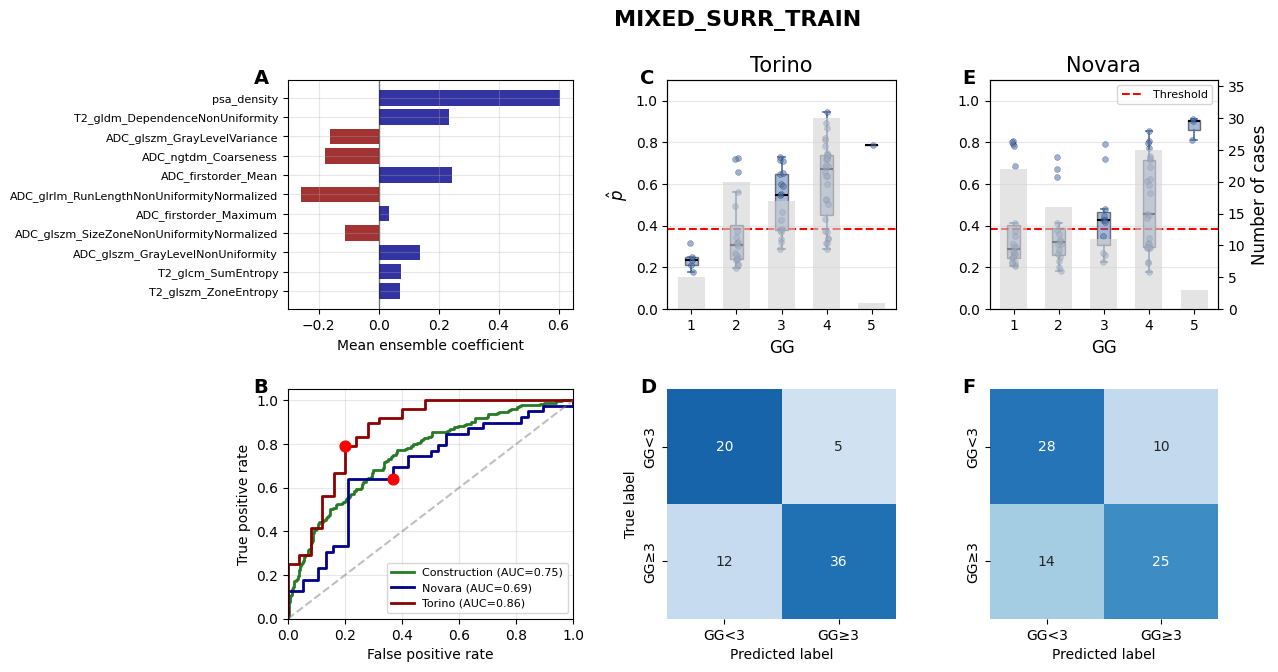

In [564]:
optimal_threshold_corrected = threshold_summary_corrected[THRESHOLD]#best_results['median_threshold_spec90_cv'].values[K_BEST_COMBINATION ] #t_youden#t_prev # default (mantiene il tuo nome)
from matplotlib.patches import Patch
from matplotlib.lines import Line2D
from sklearn.metrics import (
    roc_curve, accuracy_score, precision_score, recall_score,
    f1_score, confusion_matrix, roc_auc_score
)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# =============================================================================
# 0. ALLINEAMENTO COLONNE E COSTRUZIONE FEATURE IMPORTANCE FINALE (MOE)
# =============================================================================
train_cols = list(X_constr.columns)

X_val_tot = X_val_tot[train_cols]
X_val_novara = X_val_novara[train_cols]
X_val_torino = X_val_torino[train_cols]


all_features = X_constr.columns.tolist()
coef_rows = []

for scanner_name, expert_list in best_pipeline_corrected.experts_.items():
    for b, expert_pipeline in enumerate(expert_list):
        classifier = expert_pipeline.named_steps["classifier"]
        selector = expert_pipeline.named_steps["selector"]

        coef_full = pd.Series(0.0, index=all_features, name=f"{scanner_name}_boot{b}")

        if hasattr(classifier, "coef_"):
            selected_mask = selector.get_support(indices=False)
            selected_features = X_constr.columns[selected_mask]
            coef_full.loc[selected_features] = classifier.coef_[0]

        coef_rows.append(coef_full)

coef_matrix = pd.DataFrame(coef_rows)

feature_importance_df_final = pd.DataFrame({
    "Feature": coef_matrix.columns,
    "Coefficient": coef_matrix.mean(axis=0).values,
    "Abs_Coefficient": coef_matrix.abs().mean(axis=0).values,
    "Max_Abs_Coefficient": coef_matrix.abs().max(axis=0).values,
    "N_nonzero_experts": (coef_matrix != 0).sum(axis=0).values,
}).sort_values("Abs_Coefficient", ascending=False)


# =============================================================================
# 1. DEFINIZIONE DATASET DI VALIDAZIONE
# =============================================================================
validation_sets_gt = {
    'combined': (X_val_tot, y_val_tot),
    'novara': (X_val_novara, y_val_novara),
    'torino': (X_val_torino, y_val_torino),
}

# =============================================================================
# 2. PERFORMANCE SU CONSTRUCTION SET
# =============================================================================
y_constr_proba_corrected = best_pipeline_corrected.predict_proba(X_constr)[:, 1]
fpr_constr, tpr_constr, thresholds_constr = roc_curve(y_constr, y_constr_proba_corrected)
auc_constr = roc_auc_score(y_constr, y_constr_proba_corrected)

# =============================================================================
# 3. CONFRONTO GRID SEARCH vs VALIDATION SET
# =============================================================================
print("\n🎯 CONFRONTO PERFORMANCE: GRID SEARCH vs VALIDATION SET")

best_youden_cv = best_combination_corrected['median_youden_cv']
best_auc_cv = best_combination_corrected['median_auc_cv']

print(f"   • Best median Youden CV = {best_youden_cv:.3f}")
print(f"   • Best median AUC CV    = {best_auc_cv:.3f}")

if coefficients_corrected is not None:
    #print(f"\n⚖️ {coeff_type.upper()}:")
    for i, (_, row) in enumerate(feature_importance_df_final.head(20).iterrows(), start=1):
        coeff_type_row = "↗️ Positivo" if row['Coefficient'] > 0 else "↘️ Negativo"
        print(f"   {i}. {row['Feature']:<40} = {row['Coefficient']:+.4f} ({coeff_type_row})")

# =============================================================================
# 4. COSTRUZIONE DATAFRAME PER BOXPLOT PROBABILITÀ
# =============================================================================
df_plot = pd.concat([
    pd.DataFrame({
        "Center": "Torino",
        "Source": "GT",
        "GG": labels_tor['GG'].values,
        "p2": best_pipeline_corrected.predict_proba(X_val_torino)[:, 1]
    }),
    pd.DataFrame({
        "Center": "Novara",
        "Source": "GT",
        "GG": labels_nov["GG"].values,
        "p2": best_pipeline_corrected.predict_proba(X_val_novara)[:, 1]
    }),
], ignore_index=True)

df_plot["GG"] = df_plot["GG"].astype(int)

counts = (
    df_plot[df_plot["Source"] == "GT"]
    .groupby(["Center", "GG"])
    .size()
    .reset_index(name="n_cases")
)

max_count = counts["n_cases"].max()
sources = ["GT"]

# =============================================================================
# 5. FUNZIONE DI VALUTAZIONE
# =============================================================================
def evaluate_validation_sets(validation_sets, pipeline, threshold):
    results = {}

    for name, (X_val_i, y_val_i) in validation_sets.items():
        print(f"\n📊 Dataset: {name}")

        y_val_i = np.asarray(y_val_i)
        y_val_proba = pipeline.predict_proba(X_val_i)[:, 1]
        y_val_pred = (y_val_proba >= threshold).astype(int)

        fpr, tpr, thresholds = roc_curve(y_val_i, y_val_proba)
        auc_val = roc_auc_score(y_val_i, y_val_proba)
        acc_val = accuracy_score(y_val_i, y_val_pred)
        prec_val = precision_score(y_val_i, y_val_pred, zero_division=0)
        rec_val = recall_score(y_val_i, y_val_pred, zero_division=0)
        f1_val = f1_score(y_val_i, y_val_pred, zero_division=0)
        cm_val = confusion_matrix(y_val_i, y_val_pred)

        optimal_idx = np.argmin(np.abs(thresholds - threshold))

        tn, fp, fn, tp = cm_val.ravel()
        fpr_cm = fp / (fp + tn) if (fp + tn) > 0 else np.nan
        tpr_cm = tp / (tp + fn) if (tp + fn) > 0 else np.nan

        results[name] = {
            'y_true': y_val_i,
            'y_proba': y_val_proba,
            'y_pred': y_val_pred,
            'fpr': fpr,
            'tpr': tpr,
            'thresholds': thresholds,
            'optimal_idx': optimal_idx,
            'auc': auc_val,
            'accuracy': acc_val,
            'precision': prec_val,
            'recall': rec_val,
            'f1': f1_val,
            'cm': cm_val,
            'fpr_cm': fpr_cm,
            'tpr_cm': tpr_cm,
        }

        print(f"   • AUC      = {auc_val:.3f}")
        print(f"   • Accuracy = {acc_val:.3f}")
        print(f"   • Precision= {prec_val:.3f}")
        print(f"   • Recall   = {rec_val:.3f}")
        print(f"   • F1       = {f1_val:.3f}")

    return results

print("\n==================== GT ====================")
results_gt = evaluate_validation_sets(
    validation_sets_gt,
    best_pipeline_corrected,
    optimal_threshold_corrected
)

# =============================================================================
# FUNZIONI DI SUPPORTO
# =============================================================================
def plot_cm_row_normalized(ax, cm, title=None, xlabel=True, ylabel=True):
    cm = np.asarray(cm, dtype=float)
    row_sums = cm.sum(axis=1, keepdims=True)
    cm_norm = np.divide(cm, row_sums, out=np.zeros_like(cm), where=row_sums != 0)

    sns.heatmap(
        cm_norm,
        annot=cm.astype(int),
        fmt="d",
        cmap="Blues",
        ax=ax,
        xticklabels=["GG<3", "GG≥3"],
        yticklabels=["GG<3", "GG≥3"],
        cbar=False,
        vmin=0,
        vmax=1
    )

    if title is not None:
        ax.set_title(title, fontsize=14)

    ax.set_xlabel("Predicted label" if xlabel else "")
    ax.set_ylabel("True label" if ylabel else "")

def plot_feature_importance(ax, top_n=20):
    if feature_importance_df_final is None or len(feature_importance_df_final) == 0:
        ax.text(
            0.5, 0.5,
            "No ensemble coefficients available",
            ha="center", va="center",
            transform=ax.transAxes, fontsize=11
        )
        ax.set_xlim(0, 1)
        ax.set_ylim(0, 1)
        return

    active_features_df = feature_importance_df_final[
        feature_importance_df_final["Abs_Coefficient"] > 0
    ].head(top_n).copy()

    if len(active_features_df) > 0:
        colors = [
            "darkred" if x < 0 else "darkblue"
            for x in active_features_df["Coefficient"]
        ]

        ax.barh(
            range(len(active_features_df)),
            active_features_df["Coefficient"].values,
            color=colors,
            alpha=0.8
        )
        ax.set_yticks(range(len(active_features_df)))
        ax.set_yticklabels(active_features_df["Feature"], fontsize=8)
        ax.set_xlabel("Mean ensemble coefficient")
        ax.axvline(x=0, color="black", linestyle="-", alpha=0.5, linewidth=1)
        ax.grid(True, alpha=0.3)
        ax.invert_yaxis()
    else:
        ax.text(
            0.5, 0.5,
            "All ensemble coefficients are zero",
            ha="center", va="center",
            transform=ax.transAxes, fontsize=11
        )
        ax.set_xlim(0, 1)
        ax.set_ylim(0, 1)

def plot_roc_panel(ax):
    ax.plot(
        fpr_constr, tpr_constr,
        color="darkgreen", lw=2,
        label=f"Construction (AUC={auc_constr:.2f})",
        alpha=0.85
    )
    ax.plot(
        results_gt["novara"]["fpr"], results_gt["novara"]["tpr"],
        color="darkblue", lw=2,
        label=f'Novara (AUC={results_gt["novara"]["auc"]:.2f})'
    )
    ax.plot(
        results_gt["torino"]["fpr"], results_gt["torino"]["tpr"],
        color="darkred", lw=2,
        label=f'Torino (AUC={results_gt["torino"]["auc"]:.2f})'
    )

    ax.scatter(
        results_gt["novara"]["fpr"][results_gt["novara"]["optimal_idx"]],
        results_gt["novara"]["tpr"][results_gt["novara"]["optimal_idx"]],
        color="red", s=60, zorder=5
    )
    ax.scatter(
        results_gt["torino"]["fpr"][results_gt["torino"]["optimal_idx"]],
        results_gt["torino"]["tpr"][results_gt["torino"]["optimal_idx"]],
        color="red", s=60, zorder=5
    )

    ax.plot([0, 1], [0, 1], linestyle="--", color="gray", alpha=0.5)
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1.05)
    ax.set_xlabel("False positive rate")
    ax.set_ylabel("True positive rate")
    ax.legend(loc="lower right", fontsize=8, frameon=True)
    ax.grid(True, alpha=0.3)

def plot_probability_boxes(
    ax,
    center,
    show_left_ylabel=False,
    show_right_ylabel=False,
    add_scatter=True,
    scatter_alpha=0.55,
    scatter_size=18,
    jitter=0.045
):
    sub = df_plot[(df_plot["Center"] == center) & (df_plot["Source"] == "GT")].copy()
    ggs = sorted(sub["GG"].dropna().unique())
    base_positions = np.array(ggs, dtype=float)

    ax_count = ax.twinx()
    n = counts[counts["Center"] == center].copy()

    ax_count.bar(
        n["GG"],
        n["n_cases"],
        width=0.6,
        color="lightgray",
        alpha=0.6,
        zorder=0
    )
    ax_count.set_ylim(0, max_count * 1.2)

    if show_right_ylabel:
        ax_count.set_ylabel("Number of cases", fontsize=12)
    else:
        ax_count.tick_params(right=False, labelright=False)
        ax_count.spines["right"].set_visible(False)

    offsets = {"GT": 0.0}
    width = 0.28
    box_colors = {"GT": "#4C72B0"}

    rng = np.random.default_rng(42)

    for src in ["GT"]:
        data = [
            sub[(sub["Source"] == src) & (sub["GG"] == gg)]["p2"].dropna().values
            for gg in ggs
        ]

        pos = base_positions + offsets[src]

        bp = ax.boxplot(
            data,
            positions=pos,
            widths=width,
            patch_artist=True,
            manage_ticks=False,
            showfliers=False,
            zorder=3
        )

        for box in bp["boxes"]:
            box.set(facecolor=box_colors[src], alpha=0.5)

        for median in bp["medians"]:
            median.set(color="black", linewidth=1.5)

        for whisker in bp["whiskers"]:
            whisker.set(color=box_colors[src], linewidth=1.2)

        for cap in bp["caps"]:
            cap.set(color=box_colors[src], linewidth=1.2)

        if add_scatter:
            for gg, x0 in zip(ggs, pos):
                vals = sub[(sub["Source"] == src) & (sub["GG"] == gg)]["p2"].dropna().values
                if len(vals) == 0:
                    continue

                x_jitter = rng.uniform(-jitter, jitter, size=len(vals))
                ax.scatter(
                    np.full(len(vals), x0) + x_jitter,
                    vals,
                    s=scatter_size,
                    alpha=scatter_alpha,
                    color=box_colors[src],
                    edgecolors="black",
                    linewidths=0.25,
                    zorder=4
                )

    ax.axhline(
        y=optimal_threshold_corrected,
        color="red",
        linestyle="--",
        linewidth=1.5,
        zorder=2
    )

    ax.set_title(center, fontsize=15)
    ax.set_xticks(base_positions)
    ax.set_xticklabels(ggs)
    ax.set_xlabel("GG", fontsize=12)
    ax.grid(axis="y", alpha=0.3)

    if show_left_ylabel:
        ax.set_ylabel(r"$\hat{p}$", fontsize=12)
    else:
        ax.set_ylabel("")

    return ax_count

# =============================================================================
# FIGURA 2 x 3
# =============================================================================
fig, axes = plt.subplots(
    2, 3,
    figsize=(12, 7),
    gridspec_kw={
        "width_ratios": [1.25, 1.0, 1.0],
        "height_ratios": [1.0, 1.0],
        "wspace": 0.38,
        "hspace": 0.35
    }
)

# -------------------------------------------------------------------------
# COLONNA 1
# -------------------------------------------------------------------------
plot_feature_importance(axes[0, 0], top_n=20)
plot_roc_panel(axes[1, 0])

# -------------------------------------------------------------------------
# COLONNA 2 - TORINO
# -------------------------------------------------------------------------
count_ax_torino = plot_probability_boxes(
    axes[0, 1],
    "Torino",
    show_left_ylabel=True,
    show_right_ylabel=False
)

plot_cm_row_normalized(
    axes[1, 1],
    results_gt["torino"]["cm"],
    title=None,
    xlabel=True,
    ylabel=True
)

# -------------------------------------------------------------------------
# COLONNA 3 - NOVARA
# -------------------------------------------------------------------------
count_ax_novara = plot_probability_boxes(
    axes[0, 2],
    "Novara",
    show_left_ylabel=False,
    show_right_ylabel=True
)

plot_cm_row_normalized(
    axes[1, 2],
    results_gt["novara"]["cm"],
    title=None,
    xlabel=True,
    ylabel=False
)

axes[0, 2].sharey(axes[0, 1])
count_ax_novara.sharey(count_ax_torino)

legend_handles = [
    Line2D([0], [0], color="red", linestyle="--", linewidth=1.5, label="Threshold")
]
axes[0, 2].legend(handles=legend_handles, loc="upper right", fontsize=8, frameon=True)

panel_labels = ["A", "B", "C", "D", "E", "F"]
for ax, lab in zip(axes.flatten(order="F"), panel_labels):
    ax.text(
        -0.12, 1.05, lab,
        transform=ax.transAxes,
        fontsize=14,
        fontweight="bold",
        va="top",
        ha="left"
    )

axes[0, 1].set_ylim(0, 1.1)

import os
os.makedirs("figures_report", exist_ok=True)

plt.suptitle(DSET_TYPE, fontsize = 16, fontweight="bold")
plt.savefig(f"report_final/{DSET_TYPE}_classification.pdf", bbox_inches="tight")

# =============================================================================
# 6. SALVATAGGIO DATI PLOTTATI (PER COMBINARE RUN DIVERSE)
# =============================================================================
os.makedirs("report_final/plot_data", exist_ok=True)

plot_prefix = f"report_final/plot_data/{DSET_TYPE}_classification"

# Dati boxplot probabilita
df_plot.to_csv(f"{plot_prefix}_boxplot_probabilities.csv", index=False)
counts.to_csv(f"{plot_prefix}_boxplot_counts.csv", index=False)

# Feature importance (pannello A)
feature_importance_df_final.to_csv(f"{plot_prefix}_feature_importance.csv", index=False)

# ROC curve points (construction + validation centers)
roc_rows = []
roc_rows.extend([
    {
        "dataset": "construction",
        "point_id": i,
        "fpr": float(f),
        "tpr": float(t),
        "threshold": float(th),
    }
    for i, (f, t, th) in enumerate(zip(fpr_constr, tpr_constr, thresholds_constr))
])

for ds_name in ["torino", "novara"]:
    roc_rows.extend([
        {
            "dataset": ds_name,
            "point_id": i,
            "fpr": float(f),
            "tpr": float(t),
            "threshold": float(th),
        }
        for i, (f, t, th) in enumerate(zip(
            results_gt[ds_name]["fpr"],
            results_gt[ds_name]["tpr"],
            results_gt[ds_name]["thresholds"]
        ))
    ])
pd.DataFrame(roc_rows).to_csv(f"{plot_prefix}_roc_points.csv", index=False)

# Confusion matrices e metriche per centro (pannelli D/E/F + riepilogo)
cm_rows = []
metrics_rows = []
for ds_name in ["torino", "novara", "combined"]:
    cm = np.asarray(results_gt[ds_name]["cm"], dtype=int)
    cm_rows.extend([
        {"dataset": ds_name, "row": 0, "col": 0, "value": int(cm[0, 0])},
        {"dataset": ds_name, "row": 0, "col": 1, "value": int(cm[0, 1])},
        {"dataset": ds_name, "row": 1, "col": 0, "value": int(cm[1, 0])},
        {"dataset": ds_name, "row": 1, "col": 1, "value": int(cm[1, 1])},
    ])
    metrics_rows.append({
        "dataset": ds_name,
        "auc": float(results_gt[ds_name]["auc"]),
        "accuracy": float(results_gt[ds_name]["accuracy"]),
        "precision": float(results_gt[ds_name]["precision"]),
        "recall": float(results_gt[ds_name]["recall"]),
        "f1": float(results_gt[ds_name]["f1"]),
        "fpr_cm": float(results_gt[ds_name]["fpr_cm"]) if not np.isnan(results_gt[ds_name]["fpr_cm"]) else np.nan,
        "tpr_cm": float(results_gt[ds_name]["tpr_cm"]) if not np.isnan(results_gt[ds_name]["tpr_cm"]) else np.nan,
        "threshold_used": float(optimal_threshold_corrected),
    })

pd.DataFrame(cm_rows).to_csv(f"{plot_prefix}_confusion_matrices.csv", index=False)
pd.DataFrame(metrics_rows).to_csv(f"{plot_prefix}_metrics.csv", index=False)
print(f"Saved plot data with prefix: {plot_prefix}")
#if DSET_TYPE == "GT":
#    plt.savefig("figures_report/classification_train_on_gt_only_gt.pdf", bbox_inches="tight")
#elif DSET_TYPE == "SURROGATE":
#    plt.savefig("figures_report/classification_train_on_gt_only_gt.pdf", bbox_inches="tight")
plt.show()

## 14. FIG 3

The cell reads the CSV files of the four runs (`GT`, `MIXED_GT_TRAIN`, `SURROGATE`, `MIXED_SURR_TRAIN`) from `report_final/plot_data` and composes the figure:

- **Top two rows:** top-10 feature importances (mean ensemble coefficient) and ROC curves for the construction set, NOVARA and TORINO. Row 1: classifier trained on GT lesions (solid = tested on GT, dashed = tested on detected lesions). Row 2: classifier trained on detected lesions.
- **Bottom row:** AUC comparison (train GT/detected × test GT/detected) for NOVARA and TORINO.

AUCs are computed by integrating the saved ROC points. The AUC table is saved to `report_final/three_rows_auc_table.csv`, the figure to `report_final/three_rows_with_auc_heatmaps.pdf`.

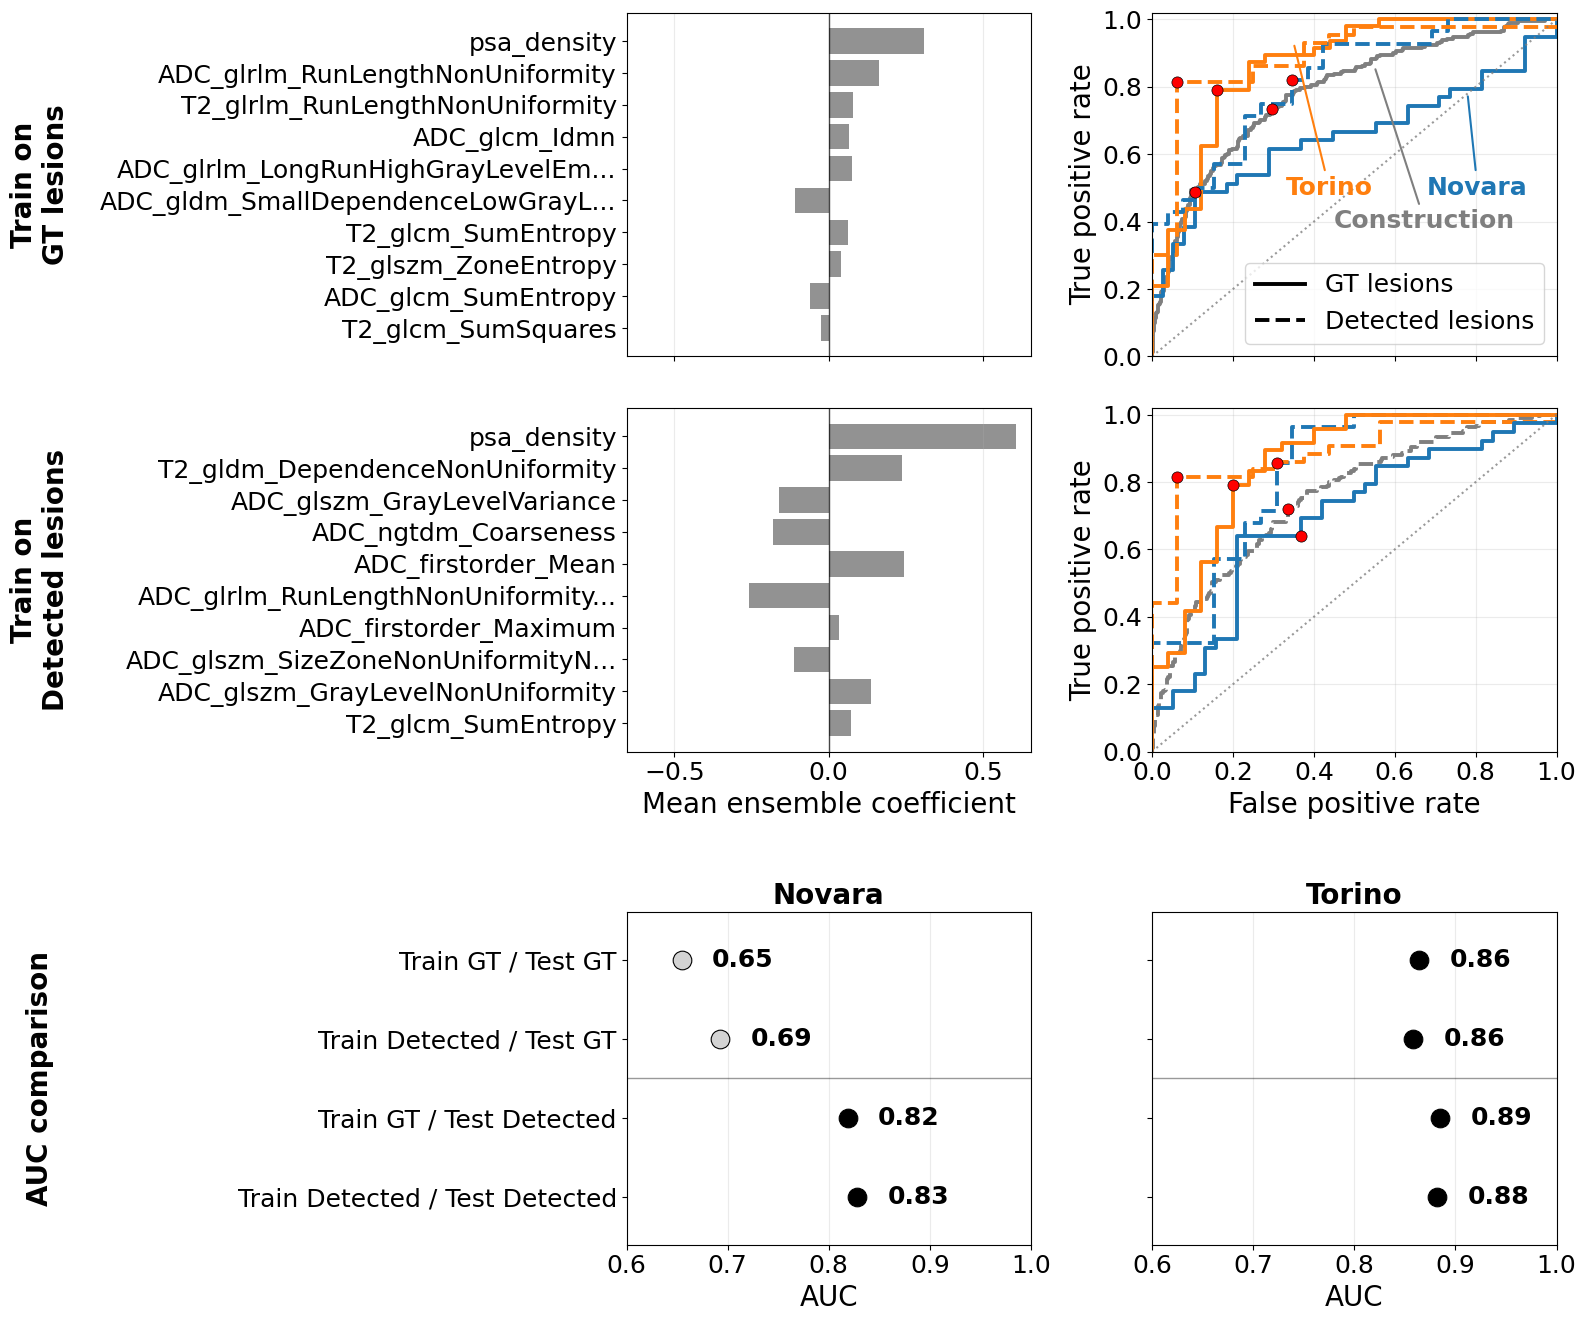

Saved figure: report_final/three_rows_with_auc_heatmaps.pdf


,row,run_tag,dataset,auc,train,test
0,GT_vs_MIXED_GT_TRAIN,GT,Construction,0.784,GT,GT
1,GT_vs_MIXED_GT_TRAIN,GT,Novara,0.655,GT,GT
2,GT_vs_MIXED_GT_TRAIN,GT,Torino,0.864,GT,GT
3,GT_vs_MIXED_GT_TRAIN,MIXED_GT_TRAIN,Novara,0.819,GT,Detected
4,GT_vs_MIXED_GT_TRAIN,MIXED_GT_TRAIN,Torino,0.885,GT,Detected
5,SURROGATE_vs_MIXED_SURR_TRAIN,SURROGATE,Construction,0.754,Detected,Detected
6,SURROGATE_vs_MIXED_SURR_TRAIN,SURROGATE,Novara,0.828,Detected,Detected
7,SURROGATE_vs_MIXED_SURR_TRAIN,SURROGATE,Torino,0.882,Detected,Detected
8,SURROGATE_vs_MIXED_SURR_TRAIN,MIXED_SURR_TRAIN,Novara,0.693,Detected,GT
9,SURROGATE_vs_MIXED_SURR_TRAIN,MIXED_SURR_TRAIN,Torino,0.858,Detected,GT


In [133]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.lines import Line2D

MAX_FEATURE_LABEL = 35

def shorten_feature_name(s, maxlen=MAX_FEATURE_LABEL):
    s = str(s)

    if len(s) <= maxlen:
        return s

    return s[:maxlen-3] + "..."


# =====================
# User-tunable settings
# =====================
TOP_N = 10

FONT_AXIS_LABEL = 20
FONT_TICK = 18
FONT_FEATURE_TICK = 18
FONT_LEGEND = 18

LINE_WIDTH = 2.8
FEATURE_BAR_COLOR = "#7f7f7f"

SHOW_CONSTRUCTION_ROC = True
SHOW_THRESHOLD_MARKERS = True
THRESHOLD_MARKER_COLOR = "red"
THRESHOLD_MARKER_SIZE = 65

base_dir = "report_final/plot_data"

# =====================
# Row configuration
# =====================
row_configs = [
    {
        "row_label": "GT_vs_MIXED_GT_TRAIN",
        "left_label": "Train on\nGT lesions",
        "tags": ["GT", "MIXED_GT_TRAIN"],
        "fi_source_tag": "GT",
        "construction_source_tag": "GT",
    },
    {
        "row_label": "SURROGATE_vs_MIXED_SURR_TRAIN",
        "left_label": "Train on\nDetected lesions",
        "tags": ["SURROGATE", "MIXED_SURR_TRAIN"],
        "fi_source_tag": "SURROGATE",
        "construction_source_tag": "SURROGATE",
    },
]

all_tags = sorted({tag for rc in row_configs for tag in rc["tags"]})
all_tags += [rc["fi_source_tag"] for rc in row_configs if rc["fi_source_tag"] not in all_tags]
all_tags += [rc["construction_source_tag"] for rc in row_configs if rc["construction_source_tag"] not in all_tags]
all_tags = list(dict.fromkeys(all_tags))

# =====================
# Visual grammar
# =====================
linestyle_by_tag = {
    "GT": "-",
    "MIXED_GT_TRAIN": "--",
    "SURROGATE": "--",
    "MIXED_SURR_TRAIN": "-",
}

color_by_center = {
    "novara": "#1f77b4",
    "torino": "#ff7f0e",
}

construction_color = "#7f7f7f"

# =====================
# Load saved run data
# =====================
roc_dict = {}
threshold_by_tag = {}
fi_dict = {}

for tag in all_tags:
    roc_path = os.path.join(base_dir, f"{tag}_classification_roc_points.csv")
    metrics_path = os.path.join(base_dir, f"{tag}_classification_metrics.csv")
    fi_path = os.path.join(base_dir, f"{tag}_classification_feature_importance.csv")

    if not os.path.exists(roc_path):
        raise FileNotFoundError(f"Missing file: {roc_path}")
    if not os.path.exists(metrics_path):
        raise FileNotFoundError(f"Missing file: {metrics_path}")
    if not os.path.exists(fi_path):
        raise FileNotFoundError(f"Missing file: {fi_path}")

    roc_dict[tag] = pd.read_csv(roc_path)
    fi_dict[tag] = pd.read_csv(fi_path)

    mdf = pd.read_csv(metrics_path)
    if "threshold_used" in mdf.columns and mdf["threshold_used"].notna().any():
        threshold_by_tag[tag] = float(mdf["threshold_used"].dropna().iloc[0])
    else:
        threshold_by_tag[tag] = np.nan

# =====================
# Prepare feature-importance panels
# =====================
fi_top_by_row = {}
fi_abs_max = 0.0

for rc in row_configs:
    row_label = rc["row_label"]
    fi_source_tag = rc["fi_source_tag"]

    fi = fi_dict[fi_source_tag][["Feature", "Coefficient", "Abs_Coefficient"]].copy()
    fi_top = (
        fi.sort_values("Abs_Coefficient", ascending=False)
        .head(TOP_N)
        .sort_values("Abs_Coefficient", ascending=True)
    )

    fi_top_by_row[row_label] = fi_top

    if not fi_top.empty:
        fi_abs_max = max(
            fi_abs_max,
            float(np.nanmax(np.abs(fi_top["Coefficient"].values)))
        )

if not np.isfinite(fi_abs_max) or fi_abs_max == 0:
    fi_abs_max = 1.0

fi_pad = 0.08 * fi_abs_max
fi_xlim = (-fi_abs_max - fi_pad, fi_abs_max + fi_pad)

# =====================
# Figure layout
# =====================
fig = plt.figure(figsize=(12, 16))

outer = fig.add_gridspec(
    2,
    1,
    height_ratios=[2.0, 0.9],
    hspace=0.3,   # spazio tra riga 2 e riga 3
)

top = outer[0].subgridspec(
    2,
    2,
    wspace=0.30,
    hspace=0.15,   # spazio tra riga 1 e riga 2
)

bottom = outer[1].subgridspec(
    1,
    2,
    wspace=0.30,
)

axes = np.array([
    [fig.add_subplot(top[0, 0]), fig.add_subplot(top[0, 1])],
    [fig.add_subplot(top[1, 0]), fig.add_subplot(top[1, 1])],
], dtype=object)

ax_hm_left = fig.add_subplot(bottom[0, 0])
ax_hm_right = fig.add_subplot(bottom[0, 1])

centers = ["novara", "torino"]
auc_rows = []

# =====================
# Main two rows: feature importance + ROC
# =====================
for r, rc in enumerate(row_configs):
    tags = rc["tags"]
    construction_source_tag = rc["construction_source_tag"]
    row_label = rc["row_label"]
    left_label = rc.get("left_label", "")

    # --------------------------------------------------
    # Feature importance
    # --------------------------------------------------
    ax_fi = axes[r, 0]
    fi_top = fi_top_by_row[row_label].copy()

    y = np.arange(len(fi_top))

    ax_fi.barh(
        y,
        fi_top["Coefficient"],
        color=FEATURE_BAR_COLOR,
        alpha=0.85,
    )

    ax_fi.axvline(
        0,
        color="black",
        linewidth=1.0,
        alpha=0.7,
    )

    
    ax_fi.set_yticks(y)
    feature_labels = [
        shorten_feature_name(f)
        for f in fi_top["Feature"]
    ]

    ax_fi.set_yticklabels(
        feature_labels,
        fontsize=FONT_FEATURE_TICK,
    )

    if r == 0:
        ax_fi.set_xlabel("")
        ax_fi.tick_params(axis="x", labelbottom=False)
    else:
        ax_fi.set_xlabel(
            "Mean ensemble coefficient",
            fontsize=FONT_AXIS_LABEL,
        )

    ax_fi.set_xlim(fi_xlim)
    ax_fi.tick_params(axis="x", labelsize=FONT_TICK)
    ax_fi.grid(axis="x", alpha=0.25)

    if left_label:
        ax_fi.text(
            -1.45,
            0.5,
            left_label,
            transform=ax_fi.transAxes,
            fontsize=FONT_AXIS_LABEL,
            fontweight="bold",
            rotation=90,
            ha="center",
            va="center",
        )

    # --------------------------------------------------
    # ROC panel
    # --------------------------------------------------
    ax_roc = axes[r, 1]

    # Construction ROC
    if SHOW_CONSTRUCTION_ROC:
        roc_constr_df = roc_dict[construction_source_tag].copy()
        roc_constr_df["dataset"] = roc_constr_df["dataset"].astype(str).str.lower()
        thr_constr = threshold_by_tag.get(construction_source_tag, np.nan)

        sub_constr = roc_constr_df[
            roc_constr_df["dataset"] == "construction"
        ].copy()

        if not sub_constr.empty:
            if "point_id" in sub_constr.columns:
                sub_constr = sub_constr.sort_values("point_id")
            else:
                sub_constr = sub_constr.sort_values(["fpr", "tpr"])

            auc_constr = np.trapz(
                sub_constr["tpr"].values,
                sub_constr["fpr"].values,
            )

            auc_rows.append({
                "row": row_label,
                "run_tag": construction_source_tag,
                "dataset": "Construction",
                "auc": float(auc_constr),
            })

            construction_ls = "--" if r == 1 else "-"

            ax_roc.plot(
                sub_constr["fpr"],
                sub_constr["tpr"],
                linewidth=LINE_WIDTH,
                color=construction_color,
                linestyle=construction_ls,
            )

            if SHOW_THRESHOLD_MARKERS and np.isfinite(thr_constr):
                idx_thr = int(
                    np.argmin(
                        np.abs(sub_constr["threshold"].values - thr_constr)
                    )
                )

                ax_roc.scatter(
                    sub_constr["fpr"].values[idx_thr],
                    sub_constr["tpr"].values[idx_thr],
                    s=THRESHOLD_MARKER_SIZE,
                    color=THRESHOLD_MARKER_COLOR,
                    edgecolors="black",
                    linewidths=0.5,
                    zorder=6,
                )

    # External validation ROC
    for tag in tags:
        roc_df = roc_dict[tag].copy()
        roc_df["dataset"] = roc_df["dataset"].astype(str).str.lower()
        thr_used = threshold_by_tag.get(tag, np.nan)

        for ds in centers:
            sub = roc_df[roc_df["dataset"] == ds].copy()

            if sub.empty:
                continue

            if "point_id" in sub.columns:
                sub = sub.sort_values("point_id")
            else:
                sub = sub.sort_values(["fpr", "tpr"])

            auc_val = np.trapz(
                sub["tpr"].values,
                sub["fpr"].values,
            )

            auc_rows.append({
                "row": row_label,
                "run_tag": tag,
                "dataset": ds.title(),
                "auc": float(auc_val),
            })

            ax_roc.plot(
                sub["fpr"],
                sub["tpr"],
                linewidth=LINE_WIDTH,
                color=color_by_center[ds],
                linestyle=linestyle_by_tag.get(tag, "-"),
            )

            if SHOW_THRESHOLD_MARKERS and np.isfinite(thr_used):
                idx_thr = int(
                    np.argmin(
                        np.abs(sub["threshold"].values - thr_used)
                    )
                )

                ax_roc.scatter(
                    sub["fpr"].values[idx_thr],
                    sub["tpr"].values[idx_thr],
                    s=THRESHOLD_MARKER_SIZE,
                    color=THRESHOLD_MARKER_COLOR,
                    edgecolors="black",
                    linewidths=0.5,
                    zorder=6,
                )

    ax_roc.plot(
        [0, 1],
        [0, 1],
        linestyle=":",
        color="gray",
        alpha=0.8,
    )

    ax_roc.set_xlim(0, 1)
    ax_roc.set_ylim(0, 1.02)

    if r == 0:
        ax_roc.set_xlabel("")
        ax_roc.tick_params(axis="x", labelbottom=False)
    else:
        ax_roc.set_xlabel(
            "False positive rate",
            fontsize=FONT_AXIS_LABEL,
        )

    ax_roc.set_ylabel(
        "True positive rate",
        fontsize=FONT_AXIS_LABEL,
    )
    ax_roc.tick_params(axis="both", labelsize=FONT_TICK)
    ax_roc.grid(alpha=0.25)


    if r == 0:
        legend_handles = [
            Line2D([0], [0], color="black", linestyle="-",
                   linewidth=LINE_WIDTH, label="GT lesions"),
            Line2D([0], [0], color="black", linestyle="--",
                   linewidth=LINE_WIDTH, label="Detected lesions"),
            #Line2D([0], [0], color=construction_color, linestyle="-",
            #       linewidth=LINE_WIDTH, label="Construction"),
            #Line2D([0], [0], color=color_by_center["novara"], linestyle="-",
            #       linewidth=LINE_WIDTH, label="Novara"),
            #Line2D([0], [0], color=color_by_center["torino"], linestyle="-",
            #      linewidth=LINE_WIDTH, label="Torino"),
        ]

        ax_roc.legend(
            handles=legend_handles,
            loc="lower right",
            fontsize=FONT_LEGEND,
            frameon=True,
        )
    
    # --------------------------------------------------
# Direct labels only on the first ROC panel
# --------------------------------------------------
    if r == 0:
        #ax_roc.text(
        #    0.56, 0.18,
        #    "solid = GT\n dashed = detected",
        #    transform=ax_roc.transAxes,
        #    fontsize=13,
        #    ha="left",
        #    va="bottom",
        #    bbox=dict(facecolor="white", edgecolor="none", alpha=0.75, pad=2)
        #)

        ax_roc.annotate(
            "Torino",
            xy=(0.35, 0.93),
            xytext=(0.33, 0.48),
            color=color_by_center["torino"],
            fontsize=18,
            fontweight="bold",
            arrowprops=dict(
                arrowstyle="-",
                lw=1.5,
                color=color_by_center["torino"]
            )
        )

        ax_roc.annotate(
            "Construction",
            xy=(0.55, 0.86),
            xytext=(0.45, 0.38),
            color=construction_color,
            fontsize=18,
            fontweight="bold",
            arrowprops=dict(
                arrowstyle="-",
                lw=1.5,
                color=construction_color
            )
        )

        ax_roc.annotate(
            "Novara",
            xy=(0.78, 0.78),
            xytext=(0.68, 0.48),
            color=color_by_center["novara"],
            fontsize=18,
            fontweight="bold",
            arrowprops=dict(
                arrowstyle="-",
                lw=1.5,
                color=color_by_center["novara"]
            )
        )

# =====================
# AUC dot plots
# =====================
auc_table = pd.DataFrame(auc_rows)

mapping = {
    "GT": ("GT", "GT"),
    "MIXED_GT_TRAIN": ("GT", "Detected"),
    "SURROGATE": ("Detected", "Detected"),
    "MIXED_SURR_TRAIN": ("Detected", "GT"),
}

auc_table[["train", "test"]] = (
    auc_table["run_tag"]
    .map(mapping)
    .apply(pd.Series)
)

plot_order = [
    ("GT", "GT"),
    ("Detected", "GT"),
    ("GT", "Detected"),
    ("Detected", "Detected"),
]

y_labels = [
    "Train GT / Test GT",
    "Train Detected / Test GT",
    "Train GT / Test Detected",
    "Train Detected / Test Detected",
]

marker_by_train = {
    "GT": "o",
    "Detected": "s",
}

color_by_test = {
    "GT": "#9ecae1",
    "Detected": "#2171b5",
}

for ax, dataset in zip([ax_hm_left, ax_hm_right], ["Novara", "Torino"]):

    tmp = auc_table[auc_table["dataset"] == dataset].copy()

    rows = []
    for y, (train, test) in enumerate(plot_order):
        val = tmp.loc[
            (tmp["train"] == train) & (tmp["test"] == test),
            "auc"
        ].iloc[0]

        rows.append({
            "y": y,
            "train": train,
            "test": test,
            "auc": val,
        })

    plot_df = pd.DataFrame(rows)

    for _, rr in plot_df.iterrows():

        point_color = "LightGray" if rr["auc"] < 0.70 else "Black"

        ax.scatter(
            rr["auc"],
            rr["y"],
            s=180,
            marker="o",
            color=point_color,
            edgecolor="black",
            linewidth=0.8,
            zorder=3,
        )

        ax.text(
            rr["auc"] + 0.03,
            rr["y"],
            f"{rr['auc']:.2f}",
            va="center",
            ha="left",
            fontsize=FONT_TICK,
            fontweight="bold",
        )
    
    

    # horizontal visual grouping: GT-test vs Detected-test
    ax.axhline(1.5, color="black", linewidth=1.0, alpha=0.4)

    ax.set_xlim(0.6, 1.0)
    ax.set_ylim(-0.6, len(plot_order) - 0.4)
    ax.invert_yaxis()

    ax.set_yticks(range(len(y_labels)))
    if dataset == "Novara":
        ax.set_yticklabels(y_labels, fontsize=FONT_TICK)
        ax.set_ylabel("")
    else:
        ax.set_yticklabels([])
        ax.set_ylabel("")

    ax.set_xlabel("AUC", fontsize=FONT_AXIS_LABEL)
    ax.set_title(dataset, fontsize=FONT_AXIS_LABEL, weight="bold")

    ax.tick_params(axis="x", labelsize=FONT_TICK)
    ax.grid(axis="x", alpha=0.25)

ax_hm_left.text(
    -1.45,
    0.5,
    "AUC comparison",
    transform=ax_hm_left.transAxes,
    fontsize=FONT_AXIS_LABEL,
    fontweight="bold",
    rotation=90,
    ha="center",
    va="center",
)

# legend
legend_handles = [
    Line2D([0], [0], marker="o", color="w",
           markerfacecolor="white", markeredgecolor="black",
           markersize=12, label="Train GT"),
    Line2D([0], [0], marker="s", color="w",
           markerfacecolor="white", markeredgecolor="black",
           markersize=12, label="Train detected"),
    Line2D([0], [0], marker="o", color="w",
           markerfacecolor=color_by_test["GT"], markeredgecolor="black",
           markersize=12, label="Test GT"),
    Line2D([0], [0], marker="o", color="w",
           markerfacecolor=color_by_test["Detected"], markeredgecolor="black",
           markersize=12, label="Test detected"),
]

"""
ax_hm_right.legend(
    handles=legend_handles,
    loc="lower left",
    fontsize=FONT_LEGEND - 2,
    frameon=True,
)
"""



# =====================
# Save
# =====================
os.makedirs("report_final", exist_ok=True)

out_path_combo = "report_final/three_rows_with_auc_heatmaps.pdf"

plt.savefig(out_path_combo, bbox_inches="tight")
plt.show()

print(f"Saved figure: {out_path_combo}")

# Optional: save AUC table
auc_table_out = auc_table.copy()
auc_table_out["auc"] = auc_table_out["auc"].round(3)
auc_table_out.to_csv(
    "report_final/three_rows_auc_table.csv",
    index=False,
)

display(auc_table_out)